# pyQuil Tutorial: Simulation (QVM only, no QCS account needed)

A tour of pyQuil's local simulation tools: programs & gates, the `QuantumComputer`, the
wavefunction simulator, the compiler, noise modeling, and advanced usage (multithreading,
qubit placeholders, classical control flow, Pauli operator algebra). Everything here runs
against the local Quantum Virtual Machine (QVM) and `quilc` compiler — no Rigetti QCS
account required.

Everything that needs a real QPU (via QCS) instead lives in the companion notebook
**`2_experiment.ipynb`**; sections below note where that happens.

If you haven’t built the **Python (pyQuil container)** kernel and run the
**quilc (`quilc -P -S`)** and **qvm (`qvm -S`)** servers yet, run the
**0_Jupyter_Pykernel_from_Container_image** notebook to create it from `pyquil.sif`, then
select **Python (pyQuil container)** in the top-right corner (refresh the page if it isn’t
listed). Cells that call `get_qc()`, `compile()` or `run()` need the `quilc` and `qvm`
servers running — the cell below checks on that.

In [1]:
import sys, pyquil
from collections import Counter
print(sys.executable, pyquil.__version__)

/opt/venv/bin/python 4.22.0


In [2]:
!tail -n 3 quilc.log qvm.log

==> quilc.log <==
<134>1 2026-11-03T04:28:12Z r002.ib.bridges2.psc.edu quilc 34614 LOG0002 [rigetti@0000 methodName="quil_to_native_quil" requestID="b5f5505e-1f34-461b-87a7-473d45e1fa6a" wallTime="0.015" error="false"] Requested quil_to_native_quil completed
<134>1 2026-11-03T04:28:13Z r002.ib.bridges2.psc.edu quilc 34614 - - Request e8072001-8739-4512-abd1-f97397257f25 received for get_version_info
<134>1 2026-11-03T04:28:13Z r002.ib.bridges2.psc.edu quilc 34614 LOG0002 [rigetti@0000 methodName="get_version_info" requestID="e8072001-8739-4512-abd1-f97397257f25" wallTime="0.0" error="false"] Requested get_version_info completed

==> qvm.log <==
<135>1 2026-11-03T04:28:13Z r002.ib.bridges2.psc.edu qvm 34621 - - [127.0.0.1 Session:1181] Finished in 17 ms
<134>1 2026-11-03T04:28:13Z r002.ib.bridges2.psc.edu qvm 34621 - - 127.0.0.1 - [2026-11-02 23:28:13] "POST / HTTP/1.1" 200 6014 "-" "-"



## Part 1: Programs and Gates

## 1. Introduction
Qubits start in the ground state |0⟩. `X` flips qubit 0 to |1⟩. Printing a program shows its Quil code.

In [3]:
import warnings
from pyquil._deprecation import PyQuilDeprecationWarning
# Hide pyQuil 4.22's notices that the QVM is deprecated in favour of pyQuil v5
# (the QVM still works; see 0_Jupyter_Pykernel_from_Container_image.ipynb).
warnings.filterwarnings("ignore", category=PyQuilDeprecationWarning)

from pyquil import Program, get_qc
from pyquil.gates import *
import numpy as np

p = Program()
p += X(0)
print(p)

X 0



To read results, **declare** classical memory and **measure** into it:

In [4]:
p = Program()
ro = p.declare('ro', 'BIT', 1)
p += X(0)
p += MEASURE(0, ro[0])
print(p)

DECLARE ro BIT[1]
X 0
MEASURE 0 ro[0]



In [5]:
#print(get_qc.__doc__)

Run on the Quantum Virtual Machine (QVM) — expect `[[1]]`:

In [6]:
qc = get_qc('1q-qvm')
executable = qc.compile(p)
result = qc.run(executable)
print(result.get_register_map().get('ro'))

[[1]]


## 2. Standard Gate Set
| Type | Gates |
|---|---|
| Pauli | `I`, `X`, `Y`, `Z` |
| Hadamard | `H` |
| Phase | `PHASE(θ)`, `S`, `T` |
| Controlled phase | `CZ`, `XY`, `CPHASE00(α)`, `CPHASE01(α)`, `CPHASE10(α)`, `CPHASE(α)` |
| Rotations | `RX(θ)`, `RY(θ)`, `RZ(θ)` |
| Controlled X | `CNOT`, `CCNOT` |
| Swap | `SWAP`, `CSWAP`, `ISWAP`, `PSWAP(α)` |

Parametric gates take float arguments.

## 3. Declaring Memory
Classical memory must be declared: `p.declare(name, memory_type='BIT', memory_size=1, shared_region=None, offsets=None)`.
- `memory_type`: `'BIT'`, `'REAL'`, `'OCTET'`, or `'INTEGER'`
- `shared_region` / `offsets`: memory aliasing

⚠️ `.declare()` returns a memory reference, not the Program, so it can't be chained.

In [7]:
p = Program()
ro = p.declare('ro', 'BIT', 16)
theta = p.declare('theta', 'REAL')
print(p)

DECLARE ro BIT[16]
DECLARE theta REAL[1]



## 4. Measurement
Use `MEASURE(qubit, memory_ref)`. Example: a Bell state measured on two qubits.

In [8]:
p = Program()
ro = p.declare('ro', 'BIT', 2)
p += H(0)
p += CNOT(0, 1)
p += MEASURE(0, ro[0])
p += MEASURE(1, ro[1])
print(p)

DECLARE ro BIT[2]
H 0
CNOT 0 1
MEASURE 0 ro[0]
MEASURE 1 ro[1]



Measuring a list of qubits in a loop:

In [9]:
p = Program()
qubits = [5, 6, 7]
ro = p.declare('ro', 'BIT', len(qubits))
for i, q in enumerate(qubits):
    p += MEASURE(q, ro[i])
print(p)

DECLARE ro BIT[3]
MEASURE 5 ro[0]
MEASURE 6 ro[1]
MEASURE 7 ro[2]



### Number of trials (shots)
`.wrap_in_numshots_loop(n)` runs the program `n` times.

In [10]:
p = Program()
ro = p.declare('ro', 'BIT', 2)
p += H(0)
p += CNOT(0, 1)
p += MEASURE(0, ro[0])
p += MEASURE(1, ro[1])
p.wrap_in_numshots_loop(1000)

qc = get_qc('2q-qvm')
bits = qc.run(qc.compile(p)).get_register_map().get('ro')
counts = dict(Counter("".join(map(str, row)) for row in bits))
print(counts) 

{'00': 482, '11': 518}


### Fixed-count loop in Quil
`.with_loop()` wraps the body in a Quil-level loop (using a counter register and labels) instead of a shot loop.

In [11]:
from pyquil.quilatom import Label

p = Program(H(0), CNOT(0, 1))
ro = p.declare("ro", "BIT", 2)
p.measure(0, ro[0])
p.measure(1, ro[1])
shot_count = p.declare("shot_count", "INTEGER")

looped_program = p.with_loop(1000, shot_count, Label("start-loop"), Label("end-loop"))
print(looped_program.out())

qc = get_qc("2q-qvm")
results = qc.run(looped_program).get_register_map().get('ro')
counts = dict(Counter("".join(map(str, row)) for row in results))
print(counts)

DECLARE ro BIT[2]
DECLARE shot_count INTEGER[1]
MOVE shot_count[0] 1000
LABEL @start-loop
H 0
CNOT 0 1
MEASURE 0 ro[0]
MEASURE 1 ro[1]
SUB shot_count[0] 1
JUMP-UNLESS @end-loop shot_count[0]
JUMP @start-loop
LABEL @end-loop

{'11': 1}


## 5. Parametric Compilation
Compile a program **template** once, then supply parameter values at run time — much faster than recompiling for every value. Unset memory defaults to zero.

In [12]:
qubit = 0
p = Program()
ro = p.declare("ro", "BIT", 1)
theta_ref = p.declare("theta", "REAL")

p += RX(np.pi / 2, qubit)
p += RZ(theta_ref, qubit)
p += RX(-np.pi / 2, qubit)
p += MEASURE(qubit, ro[0])

In [13]:
qc = get_qc("1q-qvm")
executable = qc.compile(p)

# one memory map per theta value
memory_maps = [{"theta": [theta]} for theta in np.linspace(0, 2 * np.pi, 200)]
#print(memory_maps)
parametric_measurements = qc.run_with_memory_map_batch(executable, memory_maps)
print(len(parametric_measurements))

200


## 6. Gate Modifiers
- **`DAGGER`** – adjoint: `DAGGER RX(pi/3) 0` ≡ `RX(-pi/3) 0`
- **`CONTROLLED`** – adds a control qubit: `CCNOT 0 1 2` ≡ `CONTROLLED CNOT 0 1 2` ≡ `CONTROLLED CONTROLLED X 0 1 2`
- **`FORKED`** – picks parameters based on a control qubit `c`: uses `G(u…)` if `c=0`, `G(v…)` if `c=1`

In Python, use `.dagger()`, `.controlled()`, `.forked()`:

In [14]:
print(Program(RX(np.pi/3, 0).dagger()))
print(Program(X(1).controlled(0)))
print(Program(X(2).controlled(0).controlled(1)))
print(Program(X(2).controlled([0, 1])))
print(Program(X(0), X(1).controlled(0), X(0)))
print(Program(RX(np.pi/2, 1).forked(0, [np.pi])))

DAGGER RX(1.0471975511965976) 0

CONTROLLED X 0 1

CONTROLLED CONTROLLED X 1 0 2

CONTROLLED CONTROLLED X 1 0 2

X 0
CONTROLLED X 0 1
X 0

FORKED RX(1.5707963267948966, 3.141592653589793) 0 1



## 7. Defining New Gates
Create a custom gate from a unitary matrix with `DefGate`, then get a constructor for it. The definition must be added to the program. We need to use both definition (sqrt_x_definition) and gate (SQRT-X) operation.

In [15]:
from pyquil.quil import DefGate

sqrt_x = np.array([[0.5+0.5j, 0.5-0.5j],
                   [0.5-0.5j, 0.5+0.5j]])

sqrt_x_definition = DefGate("SQRT-X", sqrt_x)
SQRT_X = sqrt_x_definition.get_constructor()

p = Program()
p += sqrt_x_definition
p += SQRT_X(0)
print(p)

DEFGATE SQRT-X AS MATRIX:
    0.5+0.5i, 0.5-0.5i
    0.5-0.5i, 0.5+0.5i

SQRT-X 0



Multi-qubit gates work the same way (here: `X ⊗ √X`):

In [16]:
x_gate_matrix = np.array([[0.0, 1.0], [1.0, 0.0]])
x_sqrt_x = np.kron(x_gate_matrix, sqrt_x)

x_sqrt_x_definition = DefGate("X-SQRT-X", x_sqrt_x)
X_SQRT_X = x_sqrt_x_definition.get_constructor()

p = Program(x_sqrt_x_definition, X_SQRT_X(0, 1))
print(p)

DEFGATE X-SQRT-X AS MATRIX:
    0, 0, 0.5+0.5i, 0.5-0.5i
    0, 0, 0.5-0.5i, 0.5+0.5i
    0.5+0.5i, 0.5-0.5i, 0, 0
    0.5-0.5i, 0.5+0.5i, 0, 0

X-SQRT-X 0 1



### Parametric gates
Use `Parameter` and Quil functions (`quil_sin`, `quil_cos`, `quil_sqrt`, `quil_exp`, `quil_cis`) in the matrix. Example: controlled-RX.

In [17]:
from pyquil.quilatom import Parameter, quil_sin, quil_cos
from pyquil.quilbase import DefGate

theta = Parameter('theta')
crx = np.array([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, quil_cos(theta / 2), -1j * quil_sin(theta / 2)],
    [0, 0, -1j * quil_sin(theta / 2), quil_cos(theta / 2)]
])

gate_definition = DefGate('CRX', crx, [theta])
CRX = gate_definition.get_constructor()

p = Program()
p += gate_definition
p += H(0)
p += CRX(np.pi/2)(0, 1)
print(p)

DEFGATE CRX(%theta) AS MATRIX:
    1, 0, 0, 0
    0, 1, 0, 0
    0, 0, cos(%theta/2), -1.0i*sin(%theta/2)
    0, 0, -1.0i*sin(%theta/2), cos(%theta/2)

H 0
CRX(1.5707963267948966) 0 1



### Permutation gates
Gates that just permute basis states can be written compactly with `DefPermutationGate` instead of a full matrix. Both below define CCNOT:

In [18]:
from pyquil.quilbase import DefPermutationGate

ccnot_matrix = np.eye(8, dtype=int)
ccnot_matrix[[6, 7]] = ccnot_matrix[[7, 6]]
ccnot_gate = DefGate("MATRIX_CCNOT", ccnot_matrix)

ccnot_perm = DefPermutationGate("PERMUTATION_CCNOT", [0, 1, 2, 3, 4, 5, 7, 6])
print(Program(ccnot_perm))

DEFGATE PERMUTATION_CCNOT AS PERMUTATION:
    0, 1, 2, 3, 4, 5, 7, 6




## 8. Pragmas
`PRAGMA` directives control how programs are compiled/simulated without changing their meaning.

### Qubit rewiring
The compiler may relabel qubits to fit the hardware. `INITIAL_REWIRING` sets the strategy:
- `"GREEDY"` – let the compiler choose good qubits
- `"NAIVE"` – keep your original qubit labels

In [19]:
from pyquil.quil import Pragma

p = Program(Pragma('INITIAL_REWIRING', ['"GREEDY"']))
p += X(3)
print(p)

p_naive = Program(Pragma('INITIAL_REWIRING', ['"NAIVE"']), X(3))
print(p_naive)

PRAGMA INITIAL_REWIRING "GREEDY"
X 3

PRAGMA INITIAL_REWIRING "NAIVE"
X 3



## 9. Delays
`DELAY(qubit, seconds)` inserts a wait. ⚠️ `DELAY` (and other Quil-T instructions) aren't supported by QVM/quilc — strip them when simulating. (`PRAGMA DELAY` is deprecated in v4.)

In [20]:
from pyquil.api import QVM

qc = get_qc("2q-qvm")
p = Program(H(0))
p += DELAY(0, 200e-9)

if isinstance(qc.qam, QVM):
    p = p.remove_quil_t_instructions()
else:
    p = qc.compiler.native_quil_to_executable(p)

qc.run(p)

QAMExecutionResult(executable=Program { calibrations: Calibrations { calibrations: CalibrationSet { data: [] }, measure_calibrations: CalibrationSet { data: [] } }, extern_pragma_map: ExternPragmaMap({}), frames: FrameSet { frames: {} }, memory_regions: {}, waveforms: {}, gate_definitions: {}, instructions: [Gate(Gate { name: "H", parameters: [], qubits: [Fixed(0)], modifiers: [] })], used_qubits: {Fixed(0)} }, data=ExecutionData { result_data: Qvm(QvmResultData { memory: {} }), duration: None })

## 10. Ways to Construct Programs
All of the following produce the same program (`X 0; Y 1`). Using `+=` is preferred.

In [21]:
p = Program(); p += X(0); p += Y(1); print(p)      # preferred
print(Program(X(0), Y(1)))                          # instructions in constructor
print(Program(X(0)) + Program(Y(1)))                # composing programs
print(Program("X 0\nY 1"))                         # raw Quil, newline
print(Program("X 0", "Y 1"))                        # raw Quil, comma-separated
print(Program().inst(X(0)).inst(Y(1)))              # chained .inst (less preferred)

X 0
Y 1

X 0
Y 1

X 0
Y 1

X 0
Y 1

X 0
Y 1

X 0
Y 1



## Part 2: The Quantum Computer

# pyQuil Tutorial: The Quantum Computer

*Condensed from the [pyQuil docs, v4.17](https://pyquil-docs.rigetti.com/en/stable/the_quantum_computer.html).*


## The Quantum Virtual Machine (QVM)

The QVM implements the Quantum Abstract Machine described in *A Practical Quantum Instruction Set Architecture*. It is written in ANSI Common Lisp and executes Quil programs. It ships with the Quil SDK and runs locally on your machine (see the QVM README or `qvm --help` for command-line usage).

pyQuil also has a **wavefunction simulator** for building and inspecting a program's wavefunction; see the next notebook.

## The Quantum Processing Unit (QPU)

To use a QPU you need a Quantum Cloud Services (QCS) account. Once authorized, you can submit jobs to a QPU from pyQuil, and your QCS dashboard lists the available processors.

## The `QuantumComputer`

`QuantumComputer` bundles the three objects you need to build and run programs:

- **`.qam`** — the quantum abstract machine, a `QVM` or `QPU` object
- **`.compiler`** — optimizes Quil and converts it into a form the QAM accepts
- **`.quantum_processor`** — the topology and Instruction Set Architecture (ISA): which 1-qubit and 2-qubit gates are supported

These subcomponents are always mutually compatible: a QPU-based `.qam` comes with a matching `QPUCompiler` and `.quantum_processor`.

### Instantiation

Create one with `get_qc()`:

```python
def get_qc(name: str, *, as_qvm: bool = None, noisy: bool = None, ...) -> QuantumComputer:
```

In [22]:
import warnings
%matplotlib inline
from pyquil._deprecation import PyQuilDeprecationWarning
# Hide pyQuil 4.22's notices that the QVM is deprecated in favour of pyQuil v5
# (the QVM still works; see 0_Jupyter_Pykernel_from_Container_image.ipynb).
warnings.filterwarnings("ignore", category=PyQuilDeprecationWarning)

from pyquil import get_qc

QPU_NAME = "Aspen-M-3"

# Get a QPU                                   # Requires QCS access
# qc = get_qc(QPU_NAME)

# Get a QVM with the same topology as the QPU  # Requires QCS access
# qc = get_qc(QPU_NAME, as_qvm=True)

# A fully connected QVM
number_of_qubits = 10
qc = get_qc(f"{number_of_qubits}q-qvm")
qc

QuantumComputer[name="10q-qvm"]

> **Note:** You must join QCS to access specific quantum processors.
>
> **Note:** To connect to a local QVM, the QVM must be running in server mode (`qvm -S`).

### Methods

A typical workflow:

In [23]:
from pyquil import get_qc, Program
from pyquil.gates import *

qc = get_qc('9q-square-qvm')

qubits = qc.qubits()
print(qubits)

p = Program()
# ... build program

compiled_program = qc.compile(p)

results = qc.run(compiled_program)

[0, 1, 2, 3, 4, 5, 6, 7, 8]


> **Note:** Both a QVM server and a `quilc` server must be running to compile and execute programs.

#### The `.run(...)` method

You are responsible for compiling your program before calling `.run()`:

In [24]:
from pyquil import Program, get_qc
from pyquil.gates import X, MEASURE

qc = get_qc("8q-qvm")

p = Program()
ro = p.declare('ro', 'BIT', 2)
p += X(0)
p += MEASURE(0, ro[0])
p += MEASURE(1, ro[1])
p.wrap_in_numshots_loop(5)

executable = qc.compile(p)
result = qc.run(executable)
bitstrings = result.get_register_map().get("ro")
print(bitstrings)

[[1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]]


Expected output:

```
[[1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]]
```

The outer list enumerates trials (one per shot from `wrap_in_numshots_loop`). The inner list enumerates the values stored in the memory region `ro`, our readout register. Because of the `X` gate, qubit 0 always reads `1`.

> **Tip:** Extract qubit 0's results with `numpy.array(bitstrings)[:, 0]`.

In [25]:
import numpy as np
print(np.array(bitstrings)[:, 0])

[1 1 1 1 1]


The result also carries execution metadata beyond the readout data, such as run duration — see `QAMExecutionResult`.

#### `.execute` and `.get_result`

`.run(...)` wraps two lower-level methods: `.execute(...)` and `.get_result(...)`. `.run()` looks synchronous, but some backends (such as live QPUs) run asynchronously. For finer control or concurrent execution, call these methods directly:

In [26]:
job_handle = qc.qam.execute(executable)
result = qc.qam.get_result(job_handle)
print(result.get_register_map().get("ro"))

[[1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]]


## Simulating the QPU using the QVM

`QAM` methods behave the same whether the target is a QVM or a QPU. As long as the topologies match, a program compiled and run on one will run on the other — which makes the QVM ideal for testing before using QPU time.

> *(Requires QCS access — see `2_experiment.ipynb`.)*

With `as_qvm=True` you get a QVM with the same topology as the named QPU. For noise models, see the *Noise and quantum computation* notebook.

### Differences between a QVM- and a QPU-based `QuantumComputer`

For QVM targets, `qc.qam` is a `QVM` and `qc.compiler` is a `QVMCompiler`. For QPU targets, `qc.qam` is a `QPU` and `qc.compiler` is a `QPUCompiler`. They share common interfaces (`QAM` and `AbstractCompiler`), but each may have backend-specific methods. Use type checks to access those safely:

In [27]:
from pyquil import get_qc
from pyquil.api import QPUCompiler

qc = get_qc("2q-qvm")  # or "Aspen-M-3"

if isinstance(qc.compiler, QPUCompiler):
    # Working with a QPU - refresh calibrations
    qc.compiler.get_calibration_program(force_refresh=True)
else:
    print("QVM target: no calibrations to refresh")

QVM target: no calibrations to refresh


#### Requesting a job cancellation

While a job is pending on a QPU, you can cancel it with `cancel` (not available on the QVM). Check the QAM type first:

In [28]:
from pyquil.api import QPU
from pyquil import Program
from pyquil.gates import X, MEASURE

p = Program()
ro = p.declare('ro', 'BIT', 1)
p += X(0)
p += MEASURE(0, ro[0])

job_handle = qc.qam.execute(qc.compile(p))

if isinstance(qc.qam, QPU):
    try:
        qc.qam.cancel(job_handle)
        print("Job was cancelled")
    except Exception:  # the docs catch QpuApiError, raised by the QCS SDK
        # If this error was raised, then the job failed to be cancelled.
        result = qc.qam.get_result(job_handle)
else:
    print("QVM target: cancellation not supported")

QVM target: cancellation not supported


### Providing your own quantum processor topology

You can define a custom topology by specifying qubits and edges:

> *(Requires QCS access — see `2_experiment.ipynb`.)*

A local-only variant that doesn't need QCS — a 4-qubit ring:

[0, 1, 2, 3]
[(0, 1), (0, 3), (1, 2), (2, 3)]


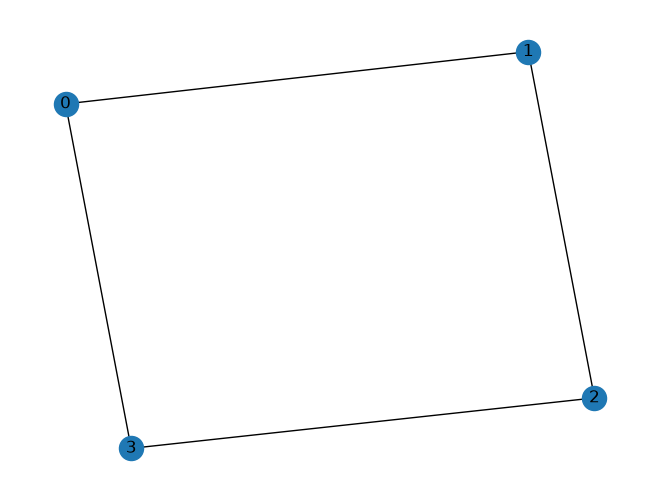

In [29]:
import networkx as nx
import matplotlib.pyplot as plt
from pyquil.quantum_processor import NxQuantumProcessor
ring = nx.cycle_graph(4)
ring_processor = NxQuantumProcessor(ring)
print(ring_processor.qubits())
print(ring_processor.edges())
nx.draw(ring, with_labels=True)
plt.show()

With your custom processor, set `qc.compiler.quantum_processor` to it, or use it when creating new objects.

## Part 3: The Wavefunction Simulator

# pyQuil Tutorial: The Wavefunction Simulator

*Condensed from the [pyQuil docs, v4.17](https://pyquil-docs.rigetti.com/en/stable/wavefunction_simulator.html).*

$\newcommand{\ket}[1]{\left|#1\right\rangle}\newcommand{\bra}[1]{\left\langle#1\right|}\newcommand{\tr}[1]{\mathrm{Tr}\left[#1\right]}$

The wavefunction simulator lets you inspect the wavefunction of the quantum state your program prepares. Because quantum information is probabilistic, programs on a QPU or QVM return a distribution of outcomes, and you'd aggregate many trials (tens to 100k+) to estimate it.

With the wavefunction simulator you can see the distribution directly, without sampling — a big time saver for small programs.

In [30]:
import warnings
from pyquil._deprecation import PyQuilDeprecationWarning
# Hide pyQuil 4.22's notices that the QVM is deprecated in favour of pyQuil v5
# (the QVM still works; see 0_Jupyter_Pykernel_from_Container_image.ipynb).
warnings.filterwarnings("ignore", category=PyQuilDeprecationWarning)

from pyquil import Program
from pyquil.gates import *
from pyquil.api import WavefunctionSimulator

wf_sim = WavefunctionSimulator()
coin_flip = Program(H(0))
wavefunction = wf_sim.wavefunction(coin_flip)

The return value is a `Wavefunction` object that stores the amplitudes of the quantum state. Printing it shows the amplitudes as a sum of computational basis states:

In [31]:
print(wavefunction)

(0.7071067812+0j)|0> + (0.7071067812+0j)|1>


Expected output: `(0.7071067812+0j)|0> + (0.7071067812+0j)|1>`

You can index into the amplitudes directly, or get a dictionary of outcome probabilities:

In [32]:
import numpy as np
np.set_printoptions(legacy="1.21")

assert wavefunction[0] == 1 / np.sqrt(2)
# The amplitudes are stored as a numpy array on the Wavefunction object
print(wavefunction.amplitudes)
prob_dict = wavefunction.get_outcome_probs()  # extracts the probabilities of outcomes as a dict
print(prob_dict)
print(prob_dict.keys())  # these store the bitstring outcomes
assert len(wavefunction) == 1  # gives the number of qubits

[0.70710678+0.j 0.70710678+0.j]
{'0': 0.4999999999999999, '1': 0.4999999999999999}
dict_keys(['0', '1'])


Remember: `wavefunction` is a debugging tool for small systems. The full wavefunction cannot feasibly be obtained from a real quantum processor.

## Multi-qubit basis enumeration

The `WavefunctionSimulator` enumerates bitstrings with qubit `0` as the **least significant bit (LSB), i.e., on the *right* end of the bitstring**:

| bitstring | qubit_(n-1) | … | qubit_2 | qubit_1 | qubit_0 |
|-----------|-------------|---|---------|---------|---------|
| 1…101     | 1           | … | 1       | 0       | 1       |
| 0…110     | 0           | … | 1       | 1       | 0       |

This is the opposite of the convention common in the literature, where the lowest-index qubit is on the left (**for example, CUDA-Q**). The vector representation assumes the canonical ordering of basis elements — for two qubits, `00, 01, 10, 11`. In Dirac notation, the tensor product of two degrees of freedom isn't always understood to have a fixed order, unlike the Kronecker product of matrices (same symbol, clearly not commutative). The order matters once you write coefficient vectors or matrices:

$$\ket{0}_0 \otimes \ket{1}_1 = \ket{1}_1 \otimes \ket{0}_0 = \ket{10}_{1,0} \equiv \begin{pmatrix} 0 \\ 0 \\ 1 \\ 0 \end{pmatrix}$$

This leads to subtle but important differences in the ordering of wavefunction and multi-qubit gate matrix coefficients. In this convention the matrix

$$U_{\rm CNOT(1,0)} \equiv \begin{pmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0 \end{pmatrix}$$

corresponds to the Quil instruction `CNOT(1, 0)`, counter to how most of the field orders Kronecker products. `CNOT(0, 1)` is:

$$U_{\rm CNOT(0,1)} \equiv \begin{pmatrix} 1 & 0 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0 \\ 0 & 1 & 0 & 0 \end{pmatrix}$$

Rigetti's note on arXiv explains why this basis ordering was chosen.

### Try it: see the ordering in action

In [33]:
# X on qubit 0, with qubit 1 also in the program.
# Qubit 0 is the rightmost bit, so the state prints as |01>, not |10>.
wf2 = wf_sim.wavefunction(Program(X(0), I(1)))
print(wf2)
print(wf2.get_outcome_probs())

(1+0j)|01>
{'00': 0.0, '01': 1.0, '10': 0.0, '11': 0.0}


In [34]:
# Compare the CNOT matrices with pyQuil's own gate matrix definitions
from pyquil.simulation.matrices import CNOT as CNOT_matrix
print("pyQuil CNOT matrix (control = first qubit in textbook order):")
print(CNOT_matrix.real.astype(int))

# Prepare |1> on qubit 0 and apply CNOT(0, 1): qubit 1 should flip -> |11>
print(wf_sim.wavefunction(Program(X(0), CNOT(0, 1))))
# Prepare |1> on qubit 1 and apply CNOT(1, 0): qubit 0 should flip -> |11>
print(wf_sim.wavefunction(Program(X(1), CNOT(1, 0))))

pyQuil CNOT matrix (control = first qubit in textbook order):
[[1 0 0 0]
 [0 1 0 0]
 [0 0 0 1]
 [0 0 1 0]]
(1+0j)|11>
(1+0j)|11>


## Part 4: The Quil Compiler

# pyQuil Tutorial: The Quil Compiler

*Condensed from the [pyQuil docs, v4.17](https://pyquil-docs.rigetti.com/en/stable/compiler.html).*

## Expectations for program contents

Real QPUs support a much smaller native gate set than pyQuil offers. The Quil SDK includes an optimizing compiler, **quilc**, that translates arbitrary Quil to native Quil, and native Quil to executables suitable for Rigetti hardware.

## Interacting with the compiler

### Setup

After installing the SDK, start a local compiler server with `quilc -S`. A `QuantumComputer` from `get_qc()` connects to it; use `.compile()`:

In [35]:
import warnings
from pyquil._deprecation import PyQuilDeprecationWarning
# Hide pyQuil 4.22's notices that the QVM is deprecated in favour of pyQuil v5
# (the QVM still works; see 0_Jupyter_Pykernel_from_Container_image.ipynb).
warnings.filterwarnings("ignore", category=PyQuilDeprecationWarning)

from pyquil.quil import Pragma, Program
from pyquil.api import get_qc
from pyquil.gates import CNOT, H

qc = get_qc("9q-square-qvm")

executable = qc.compile(Program(H(0), CNOT(0, 1), CNOT(1, 2)))

print(executable)

RZ(pi) 0
RX(pi/2) 0
RZ(pi/2) 0
RX(-pi/2) 0
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
CZ 1 0
RZ(pi) 1
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
RZ(-pi) 1
RX(pi/2) 2
RZ(pi/2) 2
RX(-pi/2) 2
CZ 2 1
RZ(pi) 0
RZ(pi) 1
RZ(pi) 2
RX(pi/2) 2
RZ(pi/2) 2
RX(-pi/2) 2
RZ(-pi) 2



Expected output (native gates only — `RZ`, `RX(±π/2)`, `CZ`):

```
RZ(pi/2) 0
RX(pi/2) 0
RZ(-pi/2) 1
RX(pi/2) 1
CZ 1 0
RX(-pi/2) 1
RZ(-pi/2) 2
RX(pi/2) 2
CZ 2 1
RZ(-pi/2) 0
RZ(-pi/2) 1
RX(-pi/2) 2
RZ(pi/2) 2
```

> **Note:** For a QVM, printing the executable shows readable native Quil. For a live QPU target the output is encrypted, because the program has been translated for the hardware.

### The compiler interface

The compiler is at `qc.compiler` and follows the `AbstractCompiler` interface:

- **`compiler.quil_to_native_quil(program, *, protoquil)`** — converts Quil to native Quil for the ISA. `protoquil=True` restricts input/output to *protoquil* (code executable on a QPU). Returns program metadata when the server was started with `-P`.
- **`compiler.native_quil_to_executable(nq_program)`** — converts native Quil into an executable for a QVM or QPU.

`qc.compile()` does both. The equivalent two-step version:

In [36]:
from pyquil.quil import Pragma, Program
from pyquil.api import get_qc
from pyquil.gates import CNOT, H

qc = get_qc("9q-square-qvm")

p = Program(H(0), CNOT(0, 1), CNOT(1, 2))

native_prog = qc.compiler.quil_to_native_quil(p, protoquil=True)  # the docs call this `np`
print(native_prog)

exe = qc.compiler.native_quil_to_executable(native_prog)
print("executable:\n")
print(exe)

RZ(pi) 0
RX(pi/2) 0
RZ(pi/2) 0
RX(-pi/2) 0
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
CZ 1 0
RZ(pi) 1
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
RZ(-pi) 1
RX(pi/2) 2
RZ(pi/2) 2
RX(-pi/2) 2
CZ 2 1
RZ(pi) 0
RZ(pi) 1
RZ(pi) 2
RX(pi/2) 2
RZ(pi/2) 2
RX(-pi/2) 2
RZ(-pi) 2

executable:

RZ(pi) 0
RX(pi/2) 0
RZ(pi/2) 0
RX(-pi/2) 0
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
CZ 1 0
RZ(pi) 1
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
RZ(-pi) 1
RX(pi/2) 2
RZ(pi/2) 2
RX(-pi/2) 2
CZ 2 1
RZ(pi) 0
RZ(pi) 1
RZ(pi) 2
RX(pi/2) 2
RZ(pi/2) 2
RX(-pi/2) 2
RZ(-pi) 2



### Timeouts

Complex circuits may need more compilation time:

In [37]:
qc = get_qc("2q-qvm", compiler_timeout=100)  # 100 seconds

### Legal compiler input

Programs for a QPU must have this structure:

1. an optional initial `RESET`
2. a block of native gates: `RZ(θ)` (any θ), `RX(k·π/2)` (integer k), or `CZ q0 q1` on neighboring qubits; some devices also support `XY(θ) q0 q1`
3. a block of `MEASURE` instructions

Use `protoquil=True` to guarantee QPU-compatible output:

```python
compiler.quil_to_native_quil(program, protoquil=True)
qc.compile(program, protoquil=True)
```

> **Note:** If the server was started with `-P`, `protoquil=False` overrides it; `protoquil=None` defers to the server's setting.

### Compilation metadata

When the compiler runs with `-P`, `quil_to_native_quil()` also returns statistics:

| Field | Meaning |
|---|---|
| `final_rewiring` | Logical-to-physical qubit mapping |
| `gate_depth` | Longest sequence of instructions sharing resources |
| `multiqubit_gate_depth` | Gate depth counting only multi-qubit gates |
| `gate_volume` | Total gate count |
| `program_duration` | Duration with gates executed in parallel |
| `qpu_runtime_estimation` | Estimated runtime in ms (for parametric programs, multiply by the parameter-space size) |
| `program_fidelity` | Estimated fidelity of the compiled program |
| `topological_swaps` | Number of topological swaps inserted |

In [38]:
from pyquil import get_qc, Program

qc = get_qc("8q-qvm")

p = Program("RX(pi) 0")

native_p = qc.compiler.quil_to_native_quil(p, protoquil=True)

print(native_p)
print(native_p.native_quil_metadata.qpu_runtime_estimation)

RX(pi) 0

183.51910400390625


## Region-specific compiler features through `PRAGMA`

### Preserved regions

`PRAGMA PRESERVE_BLOCK` … `PRAGMA END_PRESERVE_BLOCK` stops the compiler from modifying the enclosed instructions.

> **Warning:** If a preserved block isn't legal QPU input, it isn't guaranteed to execute.

Example: prepare a Bell state, wait, then read out:

In [39]:
preserved = Program("""
DECLARE ro BIT[2]

#   prepare a Bell state
H 0
CNOT 0 1

#   wait a while
PRAGMA PRESERVE_BLOCK
I 0
I 1
I 0
I 1
I 0
I 1
PRAGMA END_PRESERVE_BLOCK

#   and read out the results
MEASURE 0 ro[0]
MEASURE 1 ro[1]
""")
print(get_qc("9q-square-qvm").compile(preserved))

DECLARE ro BIT[2]
RZ(pi) 0
RX(pi/2) 0
RZ(pi/2) 0
RX(-pi/2) 0
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
CZ 1 0
RZ(pi) 0
RZ(pi) 1
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
RZ(-pi) 1
I 0
I 1
I 0
I 1
I 0
I 1
MEASURE 1 ro[1]
MEASURE 0 ro[0]



### Parallelizable regions

Mark sequences of commuting gates with `PRAGMA COMMUTING_BLOCKS` / `PRAGMA END_COMMUTING_BLOCKS`, and each individual sequence with `PRAGMA BLOCK` / `PRAGMA END_BLOCK`. The compiler may then reorder them.

> **Warning:** Marking blocks as commuting when they don't commute produces incorrect results.

A VQE-style example:

In [40]:
vqe_style = Program("""
DECLARE ro BIT[4]

# Stage one
H 0
H 1
H 2
H 3

# Stage two
PRAGMA COMMUTING_BLOCKS
PRAGMA BLOCK
CNOT 0 1
RZ(0.4) 1
CNOT 0 1
PRAGMA END_BLOCK
PRAGMA BLOCK
CNOT 1 2
RZ(0.6) 2
CNOT 1 2
PRAGMA END_BLOCK
PRAGMA BLOCK
CNOT 2 3
RZ(0.8) 3
CNOT 2 3
PRAGMA END_BLOCK
PRAGMA BLOCK
CNOT 0 3
RZ(0.9) 3
CNOT 0 3
PRAGMA END_BLOCK
PRAGMA END_COMMUTING_BLOCKS

# Stage three
H 0
H 1
H 2
H 3

MEASURE 0 ro[0]
MEASURE 1 ro[1]
MEASURE 2 ro[2]
MEASURE 3 ro[3]
""")
print(get_qc("9q-square-qvm").compile(vqe_style))

DECLARE ro BIT[4]
RZ(pi) 6
RX(pi/2) 6
RZ(pi/2) 6
RX(-pi/2) 6
RZ(-0.9199372448290238) 7
RX(pi/2) 7
RZ(pi) 7
RX(-pi/2) 7
RZ(2.2216554087607694) 7
RZ(pi) 8
RX(pi/2) 8
RZ(pi/2) 8
RX(-pi/2) 8
CZ 7 8
RZ(pi/2) 7
RX(pi/2) 7
RZ(0.3999999999999998) 7
RX(-pi/2) 7
RZ(-pi/2) 7
RZ(pi) 8
CZ 7 8
RZ(pi) 5
RX(pi/2) 5
RZ(pi/2) 5
RX(-pi/2) 5
RZ(pi) 8
RX(pi/2) 8
RZ(pi/2) 8
RX(-pi/2) 8
CZ 8 5
RZ(pi/2) 5
RZ(-1.8398744896580477) 8
RX(pi/2) 8
RZ(pi) 8
RX(-pi/2) 8
RZ(-0.2690781628631509) 8
XY(pi) 5 8
RZ(pi) 7
RX(pi/2) 7
RZ(pi/2) 7
RX(-pi/2) 7
RZ(-pi) 7
RX(pi/2) 8
RZ(pi/2) 8
RX(-pi/2) 8
CZ 8 7
RZ(pi) 7
RZ(pi/2) 8
RX(pi/2) 8
RZ(0.5999999999999998) 8
RX(-pi/2) 8
RZ(-pi/2) 8
CZ 8 7
RZ(2.2216554087607694) 7
RX(pi/2) 7
RZ(pi) 7
RX(-pi/2) 7
RZ(2.2216554087607694) 7
CZ 7 6
RZ(pi/2) 6
RZ(-1.8398744896580477) 7
RX(pi/2) 7
RZ(pi) 7
RX(-pi/2) 7
RZ(-0.2690781628631509) 7
XY(pi) 6 7
RZ(pi) 5
RX(pi/2) 5
RZ(pi/2) 5
RX(-pi/2) 5
CZ 8 5
RZ(pi/2) 5
RZ(-1.8398744896580477) 8
RX(pi/2) 8
RZ(pi) 8
RX(-pi/2) 8
RZ(-0.2690781628631509) 8

## Rewirings

When a multi-qubit instruction uses a qubit pair that isn't connected on the device, the compiler rearranges qubits. Comments like `# Entering rewiring: #(n0 n1 ... nk)` mean logical qubit `j` now lives on physical qubit `nj`.

### SWAPs

The compiler inserts `SWAP` gates to move instructions onto neighboring qubits. Initial swaps can be *virtual* — they only change the initial rewiring and don't appear in the output.

Example: non-neighboring qubits on a 3-qubit line `0 – 1 – 2`:

In [41]:
import networkx as nx
from pyquil import Program, get_qc
from pyquil.api import QCSClient
from pyquil.api._quantum_computer import _get_qvm_with_topology
from pyquil.gates import CZ

graph = nx.from_edgelist([(0, 1), (1, 2)])
qc = _get_qvm_with_topology(
    client_configuration=QCSClient(),
    name="line",
    topology=graph,
    noisy=False,
    qvm_type="qvm",
    compiler_timeout=30.0,
    execution_timeout=30.0,
)

p = Program(CZ(0, 2))
print(qc.compile(p))

CZ 2 1



Expected output: `CZ 2 1` then `HALT` — the swap was virtual.

A more complex program that needs real SWAPs:

In [42]:
from pyquil.gates import H, CZ

p = Program(CZ(0, 1), H(0), CZ(1, 2), CZ(0, 2))
print(qc.compile(p))

CZ 2 1
RZ(-0.9199372448290238) 2
RX(pi/2) 2
RZ(pi) 2
RX(-pi/2) 2
RZ(2.2216554087607694) 2
CZ 2 1
CZ 1 0
RZ(pi/2) 1
RZ(-1.8398744896580477) 2
RX(pi/2) 2
RZ(pi) 2
RX(-pi/2) 2
RZ(-0.2690781628631509) 2
XY(pi) 1 2
RZ(pi) 1
RX(pi/2) 1
RZ(pi/2) 1
RX(-pi/2) 1
CZ 1 0



> **Note:** A SWAP costs three CZ or three XY gates. Devices that support both can build a SWAP from two gates (one CZ and one XY).

### Initial rewiring

Control how the initial mapping is built with `PRAGMA INITIAL_REWIRING`:

```
# <type> can be NAIVE, RANDOM, PARTIAL, or GREEDY
#
# The double quotes are required.
PRAGMA INITIAL_REWIRING "<type>"
```

### The default initial rewiring strategy

Without `INITIAL_REWIRING`, the compiler picks:

- **`NAIVE`** when every instruction's qubits already satisfy the device topology
- **`PARTIAL`** otherwise

The docs illustrate these strategies on a real device topology (`Aspen-X`), which requires QCS access. The cells below use it as in the docs; the final cell reproduces the idea locally on the 3-qubit line.

> *(The `Aspen-X` examples for this section require QCS access — see `2_experiment.ipynb`. The last cell below reproduces the idea locally on the 3-qubit line.)*

#### NAIVE

Logical qubit `i` maps directly to physical qubit `i`. The compiler generally will **not** move an instruction's qubits, even if that results in poor fidelity.

> **Note:** When NAIVE mode has to rewire, the result isn't guaranteed to have optimal fidelity.

#### PARTIAL

The compiler starts with an empty logical-to-physical mapping and fills it in as it compiles, giving it the freedom to choose a mapping that optimizes the program's fidelity.

#### GREEDY

The compiler builds the initial mapping from a greedy optimization of distances between the program's qubits and the device's. It's faster than PARTIAL but gives lower-fidelity programs — use it when compile speed matters more than fidelity.

#### Which strategy should I use?

| Desired effect | Recommended strategy |
|---|---|
| Maximize program execution fidelity | `PARTIAL` |
| Keep the input program's qubits where possible | `NAIVE` |
| Faster qubit allocation at the expense of fidelity | `GREEDY` |

> **Note:** Each strategy has the drawbacks described above.

### Try it locally: compare strategies on the line topology

In [43]:
for strategy in ["NAIVE", "PARTIAL", "GREEDY"]:
    p = Program(f'PRAGMA INITIAL_REWIRING "{strategy}"', CZ(0, 2))
    print(f"--- {strategy} ---")
    print(qc.compile(p))

--- NAIVE ---
PRAGMA INITIAL_REWIRING "NAIVE"
CZ 0 1

--- PARTIAL ---
PRAGMA INITIAL_REWIRING "PARTIAL"
CZ 2 1

--- GREEDY ---
PRAGMA INITIAL_REWIRING "GREEDY"
CZ 0 1



PRAGMA INITIAL_REWIRING "GREEDY"
CZ 0 1



## Common error messages

- **`! ! ! Error: Matrices do not lie in the same projective class.`** The compiler decomposed an operator into native instructions, but the result doesn't match the original. Usually the matrix isn't unitary or a `DEFGATE` block is invalid. Rarely it's a floating-point precision issue, and recompiling may fix it. If not, contact support@rigetti.com or file a GitHub issue.

## Part 5: Noise and Quantum Computation

# pyQuil Tutorial: Noise and Quantum Computation

*Condensed from the [pyQuil docs, v4.17](https://pyquil-docs.rigetti.com/en/stable/noise.html).*

$\newcommand{\ket}[1]{\left|#1\right\rangle}\newcommand{\bra}[1]{\left\langle#1\right|}\newcommand{\tr}[1]{\mathrm{Tr}\left[#1\right]}$

## Modeling noisy quantum gates

### Pure states vs. mixed states

Errors introduce *classical* uncertainty about the quantum state. When we don't know which state the system is in, we describe it as a **mixed state**: a probabilistic mixture of wavefunctions. Mixed states are represented by **density matrices**. A pure state's density matrix is

$$\rho_\psi = \ket{\psi}\bra{\psi}$$

# From a pure state to the trace formula for expectation values

Start from the density matrix of a pure state:

$$
\rho_\psi = |\psi\rangle\langle\psi|
$$

and arrive at the expectation value of an observable $X$:

$$
\langle X \rangle_\rho = \operatorname{tr}(X\rho)
$$

## Derivation

**Step 1: pure-state expectation value.**

$$
\langle X \rangle_\psi = \langle\psi| X |\psi\rangle
$$

**Step 2: insert the identity** $I = \sum_i |i\rangle\langle i|$ for any orthonormal basis $\{|i\rangle\}$:

$$
\langle\psi| X |\psi\rangle = \sum_i \langle\psi| X |i\rangle\langle i|\psi\rangle
$$

**Step 3: reorder the scalars.** Each $\langle i|\psi\rangle$ is a number, so it can move to the front:

$$
= \sum_i \langle i|\psi\rangle\,\langle\psi| X |i\rangle
$$

**Step 4: recognize the density matrix.** Since $|\psi\rangle\langle\psi| = \rho_\psi$:

$$
= \sum_i \langle i| \rho_\psi X |i\rangle
$$

**Step 5: recognize the trace.** Since $\operatorname{tr}(A) = \sum_i \langle i|A|i\rangle$:

$$
= \operatorname{tr}(\rho_\psi X) = \operatorname{tr}(X \rho_\psi)
$$

The last equality uses the cyclic property of the trace, $\operatorname{tr}(AB) = \operatorname{tr}(BA)$.

**Result:**

$$
\boxed{\langle X \rangle_\psi = \langle\psi|X|\psi\rangle = \operatorname{tr}(X\rho_\psi)}
$$

**Note:** Pure-state density matrices satisfy $\rho^2 = \rho$. 

## Extension to mixed states

A mixed state is a classical mixture $\rho = \sum_k p_k |\psi_k\rangle\langle\psi_k|$. Its expectation value is the probability-weighted average of the pure-state values. By linearity of the trace:

$$
\langle X \rangle_\rho
= \sum_k p_k \langle\psi_k|X|\psi_k\rangle
= \sum_k p_k \operatorname{tr}(X\rho_k)
= \operatorname{tr}\!\Big(X \sum_k p_k \rho_k\Big)
= \operatorname{tr}(X\rho)
$$

So $\operatorname{tr}(X\rho)$ is the general definition for any state, pure or mixed.

For example: Classical uncertainty between two states is a weighted sum,

$$\rho = p\,\rho_1 + (1-p)\,\rho_2$$

where $p \in [0,1]$ is the classical probability of $\rho_1$.
## Quick check

Take $|\psi\rangle = |0\rangle$ and $X = Z$:

$$
\rho = \begin{pmatrix}1 & 0\\ 0 & 0\end{pmatrix},
\qquad
Z\rho = \begin{pmatrix}1 & 0\\ 0 & 0\end{pmatrix},
\qquad
\operatorname{tr}(Z\rho) = 1
$$

This matches $\langle 0|Z|0\rangle = 1$.

and expectation values are

$$\langle X \rangle_\rho = \tr{X \rho}$$



### Quantum gate errors

1. **Coherent errors** preserve purity: a perturbed unitary $\tilde{U} \neq U$ is applied instead of the ideal $U$.
2. **Incoherent errors** destroy purity. The state evolves as

$$\rho \mapsto \sum_{j=1}^m K_j\rho K_j^\dagger$$

where the **Kraus operators** $\{K_1, \dots, K_m\}$ satisfy $\sum_{j=1}^m K_j^\dagger K_j = I$ so that trace is conserved.

Coherent errors can in principle be fixed with better-calibrated control. Incoherent errors are trickier.

### Why do incoherent errors happen?

A qubit that isn't perfectly isolated co-evolves with its environment. The joint system-plus-environment evolution is unitary, but the system alone generally isn't. With $\mathcal{H} = \mathcal{H}_S \otimes \mathcal{H}_E$ and Hamiltonian

$$H = H_S \otimes I + I \otimes H_E + V$$

where $V$ couples system and environment, even a factorizable initial state evolves into an entangled one:

$$\ket{\psi_t} = e^{-i \frac{Ht}{\hbar}} \left(\ket{\psi}_{S,0}\otimes \ket{\psi}_{E,0}\right)$$

### A toy model

Assume $H_S = 0$, $H_E = 0$, weak coupling $\|tV/\hbar\|^2 \sim \epsilon \ll 1$, and $V = \sqrt{\epsilon}\, V_S \otimes V_E$ with $\bra{\psi}_{E,0} V_E\ket{\psi}_{E,0} = 0$. Joint evolution is

$$\rho \mapsto \rho' := e^{-i \frac{Vt}{\hbar}} \rho\, e^{+i \frac{Vt}{\hbar}}$$

Expanding to second order with Baker–Campbell–Hausdorff:

$$\rho' = \rho - \frac{it}{\hbar} [V, \rho] - \frac{t^2}{2\hbar^2} [V, [V, \rho]] + O(\epsilon^{3/2})$$

Tracing out the environment, with $\rho = \rho_{S,0} \otimes \rho_{E,0}$:

$$\rho_S' := \mathrm{Tr}_E[\rho'] = \rho_{S,0} - \frac{\gamma}{2} \left[ V_S^2\rho_{S,0} + \rho_{S,0} V_S^2 - 2 V_S\rho_{S,0}V_S\right]$$

where $\gamma := \frac{\epsilon t^2}{2\hbar^2}\tr{V_E^2 \rho_{E,0}} \ll 1$. This is approximately a Kraus map with $K_1 := I - \frac{\gamma}{2} V_S^2$ and $K_2 := \sqrt{\gamma}\, V_S$:

$$\rho_S \to \rho_S' = K_1\rho K_1^\dagger + K_2\rho K_2^\dagger = \rho - \frac{\gamma}{2}\left[ V_S^2 \rho + \rho V_S^2\right] + \gamma V_S\rho_S V_S + O(\gamma^2)$$

which agrees with the derivation to $O(\epsilon^{3/2})$. Similar arguments lead to the Lindblad master equation.

## Noisy gates on the QVM

You can annotate a Quil program with `PRAGMA`s that replace particular gates with imperfect (Kraus map) versions.

The QVM propagates *pure* states, so it simulates noisy gates correctly **on average over many runs**. When it applies a noisy gate, it randomly picks Kraus operator $K_j$ with probability

$$p_j := \bra{\psi}_S K_j^\dagger K_j \ket{\psi}_S$$

and produces

$$\ket{\psi'}_S = \frac{1}{\sqrt{p_j}} K_j \ket{\psi}_S$$

Over $N \gg 1$ runs, the $N_\ell \approx N p_\ell$ runs that picked $K_\ell$ average to

$$\overline{\rho_S'} \approx \sum_{\ell} K_{\ell}\ket{\psi}_S \bra{\psi}_S K_{\ell}^\dagger$$

So noisy simulations must be repeated many times to give representative results.

## Getting started

1. Develop a good noise model (e.g., from Quantum Process Tomography or Gate Set Tomography).
2. Define the Kraus operators as a list of numpy arrays: `kraus_ops = [K1, K2, ..., Km]`.
3. For a program `p`, call `p.define_noisy_gate("MY_NOISY_GATE", [q1, q2], kraus_ops)`, replacing the gate name and qubit indices.

In [44]:
import warnings
from pyquil._deprecation import PyQuilDeprecationWarning
# Hide pyQuil 4.22's notices that the QVM is deprecated in favour of pyQuil v5
# (the QVM still works; see 0_Jupyter_Pykernel_from_Container_image.ipynb).
warnings.filterwarnings("ignore", category=PyQuilDeprecationWarning)

import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np

from pyquil import Program, get_qc
from pyquil.gates import CZ, H, I, X, MEASURE
from pyquil.quilbase import Declare
from scipy.linalg import expm
from scipy.stats import binom

%matplotlib inline

In [45]:
qc = get_qc('2q-qvm')

## Example 1: Amplitude damping

Amplitude damping is an imperfect identity map with Kraus operators

$$K_1 = \begin{pmatrix} 1 & 0 \\ 0 & \sqrt{1-p} \end{pmatrix}, \qquad K_2 = \begin{pmatrix} 0 & \sqrt{p} \\ 0 & 0 \end{pmatrix}$$

where $p$ is the probability that a qubit in $\ket{1}$ decays to $\ket{0}$.

In [46]:
def damping_channel(damp_prob=.1):
    """
    Generate the Kraus operators corresponding to an amplitude damping
    noise channel.

    :params float damp_prob: The one-step damping probability.
    :return: A list [k1, k2] of the Kraus operators that parametrize the map.
    :rtype: list
    """
    damping_op = np.sqrt(damp_prob) * np.array([[0, 1],
                                                [0, 0]])

    residual_kraus = np.diag([1, np.sqrt(1-damp_prob)])
    return [residual_kraus, damping_op]

def append_kraus_to_gate(kraus_ops, g):
    """
    Follow a gate `g` by a Kraus map described by `kraus_ops`.

    :param list kraus_ops: The Kraus operators.
    :param numpy.ndarray g: The unitary gate.
    :return: A list of transformed Kraus operators.
    """
    return [kj.dot(g) for kj in kraus_ops]

def append_damping_to_gate(gate, damp_prob=.1):
    """
    Generate the Kraus operators corresponding to a given unitary
    single qubit gate followed by an amplitude damping noise channel.

    :params np.ndarray|list gate: The 2x2 unitary gate matrix.
    :params float damp_prob: The one-step damping probability.
    :return: A list [k1, k2] of the Kraus operators that parametrize the map.
    :rtype: list
    """
    return append_kraus_to_gate(damping_channel(damp_prob), gate)

In [47]:
%%time
# single step damping probability
damping_per_I = 0.02

# number of program executions
trials = 200

results_damping = []
lengths = np.arange(0, 201, 10, dtype=int)
for jj, num_I in enumerate(lengths):

    p = Program(
        Declare("ro", "BIT", 1),
        X(0),
    )
    # want increasing number of I-gates
    p.inst([I(0) for _ in range(num_I)])
    p.inst(MEASURE(0, ("ro", 0)))

    # overload identity I on qc 0
    p.define_noisy_gate("I", [0], append_damping_to_gate(np.eye(2), damping_per_I))
    p.wrap_in_numshots_loop(trials)
    qc.qam.random_seed = int(num_I)
    res = qc.run(p).get_register_map().get("ro")
    results_damping.append([np.mean(res), np.std(res) / np.sqrt(trials)])

results_damping = np.array(results_damping)

CPU times: user 57.7 ms, sys: 4.5 ms, total: 62.2 ms
Wall time: 2.98 s


In [48]:
dense_lengths = np.arange(0, lengths.max()+1, .2)
survival_probs = (1-damping_per_I)**dense_lengths
logpmf = binom.logpmf(np.arange(trials+1)[np.newaxis, :], trials,
                      survival_probs[:, np.newaxis])/np.log(10)

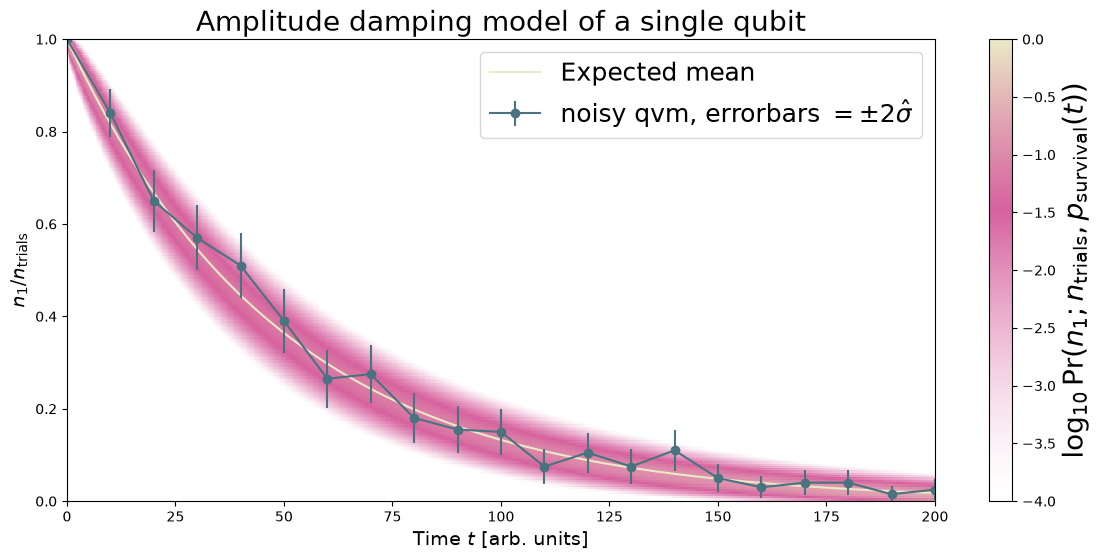

In [49]:
DARK_TEAL = '#48737F'
FUSCHIA = "#D6619E"
BEIGE = '#EAE8C6'
cm = colors.LinearSegmentedColormap.from_list('anglemap', ["white", FUSCHIA, BEIGE], N=256, gamma=1.5)

plt.figure(figsize=(14, 6))
plt.pcolor(dense_lengths, np.arange(trials+1)/trials, logpmf.T, cmap=cm, vmin=-4, vmax=logpmf.max())
plt.plot(dense_lengths, survival_probs, c=BEIGE, label="Expected mean")
plt.errorbar(lengths, results_damping[:,0], yerr=2*results_damping[:,1], c=DARK_TEAL,
             label=r"noisy qvm, errorbars $ = \pm 2\hat{\sigma}$", marker="o")
cb = plt.colorbar()
cb.set_label(r"$\log_{10} \mathrm{Pr}(n_1; n_{\rm trials}, p_{\rm survival}(t))$", size=20)

plt.title("Amplitude damping model of a single qubit", size=20)
plt.xlabel(r"Time $t$ [arb. units]", size=14)
plt.ylabel(r"$n_1/n_{\rm trials}$", size=14)
plt.legend(loc="best", fontsize=18)
plt.xlim(*lengths[[0, -1]])
plt.ylim(0, 1)
plt.show()

## Example 2: Dephased CZ gate

Dephasing is characterized by a qubit's $T_2$ time. Single-qubit dephasing has Kraus operators

$$K_1(p) = \sqrt{1-p}\, I_2, \qquad K_2(p) = \sqrt{p}\, \sigma_Z$$

where $p = (1 - \exp(-T_{\rm gate}/T_2))/2$ is the dephasing probability over one gate interval.

For two qubits there are four outcomes — no dephasing, qubit 1 dephases, qubit 2 dephases, both dephase:

$$K'_1 = K_1(p)\otimes K_1(q),\quad K'_2 = K_2(p)\otimes K_1(q),\quad K'_3 = K_1(p)\otimes K_2(q),\quad K'_4 = K_2(p)\otimes K_2(q)$$

Both dephasing and CZ are diagonal, so we compose $U_{\rm CZ}$ with each operator: $K^{\rm CZ}_j = K'_j\, U_{\rm CZ}$.

> **Note:** This isn't always accurate — real CZ gates often use non-diagonal interaction Hamiltonians — but it's a good starting point for small dephasing probabilities.

In [50]:
def dephasing_kraus_map(p=.1):
    """
    Generate the Kraus operators corresponding to a dephasing channel.

    :params float p: The one-step dephasing probability.
    :return: A list [k1, k2] of the Kraus operators that parametrize the map.
    :rtype: list
    """
    return [np.sqrt(1-p)*np.eye(2), np.sqrt(p)*np.diag([1, -1])]

def tensor_kraus_maps(k1, k2):
    """
    Generate the Kraus map corresponding to the composition
    of two maps on different qubits.

    :param list k1: The Kraus operators for the first qubit.
    :param list k2: The Kraus operators for the second qubit.
    :return: A list of tensored Kraus operators.
    """
    return [np.kron(k1j, k2l) for k1j in k1 for k2l in k2]

In [51]:
%%time
# single step damping probabilities
ps = np.linspace(.001, .5, 200)

# number of program executions
trials = 500

results = []

for jj, p in enumerate(ps):

    corrupted_CZ = append_kraus_to_gate(
        tensor_kraus_maps(
            dephasing_kraus_map(p),
            dephasing_kraus_map(p)
        ),
        np.diag([1, 1, 1, -1]))

    # make Bell-state
    p = Program(
        Declare("ro", "BIT", 2),
        H(0),
        H(1),
        CZ(0, 1),
        H(1),
    )

    p.inst(MEASURE(0, ("ro", 0)))
    p.inst(MEASURE(1, ("ro", 1)))

    # overload CZ on qc 0
    p.define_noisy_gate("CZ", [0, 1], corrupted_CZ)
    p.wrap_in_numshots_loop(trials)
    qc.qam.random_seed = jj
    res = qc.run(p).get_register_map().get("ro")
    results.append(res)

results = np.array(results)

CPU times: user 454 ms, sys: 17.8 ms, total: 471 ms
Wall time: 3.02 s


In [52]:
Z1s = (2*results[:,:,0]-1.)
Z2s = (2*results[:,:,1]-1.)
Z1Z2s = Z1s * Z2s

Z1m = np.mean(Z1s, axis=1)
Z2m = np.mean(Z2s, axis=1)
Z1Z2m = np.mean(Z1Z2s, axis=1)

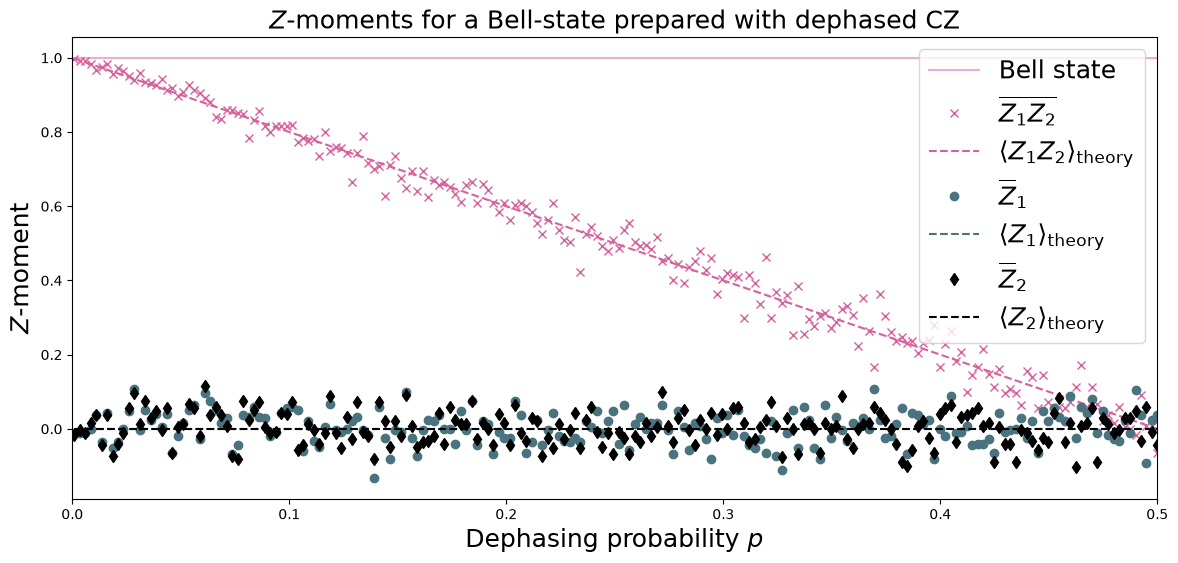

In [53]:
plt.figure(figsize=(14, 6))
plt.axhline(y=1.0, color=FUSCHIA, alpha=.5, label="Bell state")

plt.plot(ps, Z1Z2m, "x", c=FUSCHIA, label=r"$\overline{Z_1 Z_2}$")
plt.plot(ps, 1-2*ps, "--", c=FUSCHIA, label=r"$\langle Z_1 Z_2\rangle_{\rm theory}$")

plt.plot(ps, Z1m, "o", c=DARK_TEAL, label=r"$\overline{Z}_1$")
plt.plot(ps, 0*ps, "--", c=DARK_TEAL, label=r"$\langle Z_1\rangle_{\rm theory}$")

plt.plot(ps, Z2m, "d", c="k", label=r"$\overline{Z}_2$")
plt.plot(ps, 0*ps, "--", c="k", label=r"$\langle Z_2\rangle_{\rm theory}$")

plt.xlabel(r"Dephasing probability $p$", size=18)
plt.ylabel(r"$Z$-moment", size=18)
plt.title(r"$Z$-moments for a Bell-state prepared with dephased CZ", size=18)
plt.xlim(0, .5)
plt.legend(fontsize=18)

## Adding decoherence noise

Here we look at how a program behaves on a near-term device with $T_1$- and $T_2$-type noise, using `pyquil.noise.add_decoherence_noise()`. The `pyquil.noise` module also has `tensor_kraus_maps()` (multi-qubit noise), `combine_kraus_maps()` (successive noise processes) and `append_kraus_to_gate()` (appending noise to a unitary gate).

In [54]:
from pyquil.quil import Program
from pyquil.paulis import PauliSum, PauliTerm, exponentiate, exponential_map, trotterize
from pyquil.gates import MEASURE, H, Z, RX, RZ, CZ
from pyquil.quilbase import Declare
import numpy as np

### The task

Prepare $e^{i \theta XY}$ and measure it in the $Z$ basis.

In [55]:
from numpy import pi
theta = pi/3
xy = PauliTerm('X', 0) * PauliTerm('Y', 1)

### The idiomatic pyQuil program

In [56]:
prog = exponential_map(xy)(theta)
print(prog)

H 0
RX(1.5707963267948966) 1
CNOT 0 1
RZ(2.0943951023931953) 1
CNOT 0 1
H 0
RX(-1.5707963267948966) 1



### The compiled program

Real devices (and this noise model) use native gates: $I$, $RZ(\theta)$, $RX(\pm \pi/2)$, $CZ$. Here is the compiled version:

In [57]:
def get_compiled_prog(theta):
    return Program([
        RZ(-pi/2, 0),
        RX(-pi/2, 0),
        RZ(-pi/2, 1),
        RX( pi/2, 1),
        CZ(1, 0),
        RZ(-pi/2, 1),
        RX(-pi/2, 1),
        RZ(theta, 1),
        RX( pi/2, 1),
        CZ(1, 0),
        RX( pi/2, 0),
        RZ( pi/2, 0),
        RZ(-pi/2, 1),
        RX( pi/2, 1),
        RZ(-pi/2, 1),
    ])

### Scan over noise parameters

We scan three $T_1$ values (1, ≈3.16 and 10 µs) at 20 values of θ. By default $T_2 = T_1/2$, 1-qubit gates take 50 ns and 2-qubit gates take 150 ns. Identity and parametric $RZ$ gates are noiseless; $RX$ and $CZ$ get 1-qubit and 2-qubit noise respectively.

In [58]:
from pyquil import get_qc
qc = get_qc("2q-qvm")

In [59]:
t1s = np.logspace(-6, -5, num=3)
thetas = np.linspace(-pi, pi, num=20)
t1s * 1e6  # us

array([ 1.        ,  3.16227766, 10.        ])

In [60]:
from pyquil.noise import add_decoherence_noise
records = []
for theta in thetas:
    for t1 in t1s:
        prog = get_compiled_prog(theta)
        noisy = add_decoherence_noise(prog, T1=t1, T2=t1/2).inst([
            Declare("ro", "BIT", 2),
            MEASURE(0, ("ro", 0)),
            MEASURE(1, ("ro", 1)),
        ])
        bitstrings = qc.run(noisy).get_register_map().get("ro")

        # Expectation of Z0 and Z1
        z0, z1 = 1 - 2*np.mean(bitstrings, axis=0)

        # Expectation of ZZ by computing the parity of each pair
        zz = 1 - (np.sum(bitstrings, axis=1) % 2).mean() * 2

        record = {
            'z0': z0,
            'z1': z1,
            'zz': zz,
            'theta': theta,
            't1': t1,
        }
        records += [record]

### Plot the results (requires `pandas` and `seaborn`)

In [61]:
from matplotlib import pyplot as plt
import seaborn as sns
sns.set(style='ticks', palette='colorblind')

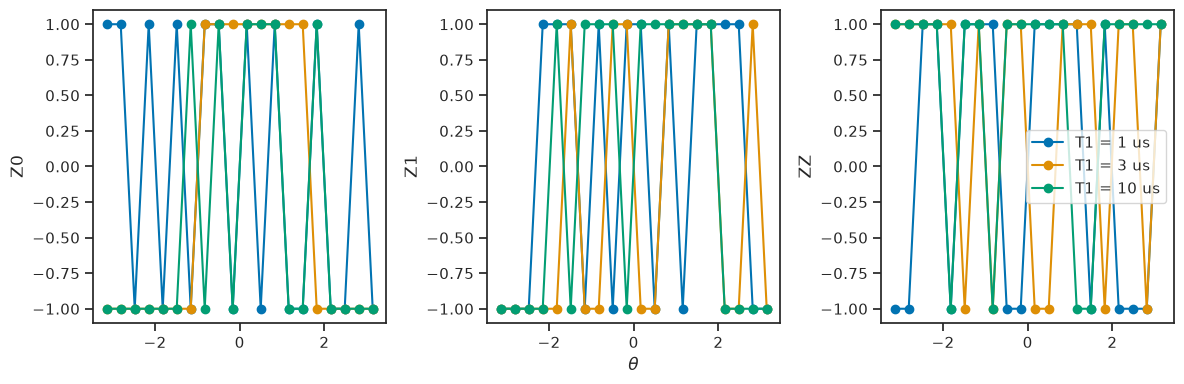

In [62]:
import pandas as pd
df_all = pd.DataFrame(records)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12,4))

for t1 in t1s:
    df = df_all.query('t1 == @t1')

    ax1.plot(df['theta'], df['z0'], 'o-')
    ax2.plot(df['theta'], df['z1'], 'o-')
    ax3.plot(df['theta'], df['zz'], 'o-', label='T1 = {:.0f} us'.format(t1*1e6))

ax3.legend(loc='best')

ax1.set_ylabel('Z0')
ax2.set_ylabel('Z1')
ax3.set_ylabel('ZZ')
ax2.set_xlabel(r'$\theta$')
fig.tight_layout()

## Modeling readout noise

Readout is corrupted by two main mechanisms:

1. **Classical readout bit-flip error** — noise on the transmission line makes a 0 look like a 1 or vice versa. Reduced by optimized readout pulses and quantum-limited amplifiers.
2. **T1-readout error** — the qubit decays during readout (which can exceed a microsecond), so a signal that starts like $\ket{1}$ ends up like $\ket{0}$. Reduced by shortening readout relative to $T_1$.

### Projective, ideal measurement

Born's rule and the projection postulate give a complete set of orthogonal projectors $P_{\mathcal{O}} := \{\Pi_x \mid x \in \mathcal{O}\}$ with $\Pi_x^\dagger = \Pi_x = \Pi_x^2$, $\Pi_x\Pi_y = \delta_{xy}\Pi_x$ and $\sum_x \Pi_x = 1$. The probability of outcome $x$ is

$$p(x) = \tr{\Pi_x \rho \Pi_x} = \tr{\Pi_x \rho}$$

and the post-measurement state is $\rho_x = \frac{1}{p(x)} \Pi_x \rho \Pi_x$. If the outcome is discarded, the best guess of the post-measurement state is

$$\rho_{\text{post measurement}} = \sum_{x\in\mathcal{O}} p(x) \rho_x = \sum_{x\in\mathcal{O}} \Pi_x \rho \Pi_x$$

### Classical readout bit-flip error

An ideal outcome $x$ passes through a noisy classical channel and becomes $x' \in \{0', 1'\}$, described by the **assignment probability matrix**

$$P_{x'|x} = \begin{pmatrix} p(0 | 0) & p(0 | 1) \\ p(1 | 0) & p(1 | 1) \end{pmatrix}$$

which has two free parameters (each column is a probability distribution). Probabilities transform as $\mathbf{p}' = P_{x'|x}\mathbf{p}$. Using Bayes' theorem, the noisy outcome probabilities are $p(x') = \tr{\rho E_{x'}}$ with

$$E_{x'} := \sum_{x\in \mathcal{O}} p(x'|x)\Pi_x \ge 0, \qquad \sum_{x'} E_{x'} = 1$$

The family $\{E_{x'}\}$ is a **positive operator valued measure (POVM)**. Its elements generally aren't orthogonal projectors, but they arise naturally here.

### How to model $T_1$ error

$T_1$ error corrupts the state during measurement and can erase pre-measurement information. The most general description uses measurement instruments; in practice, model it as a $T_1$ damping Kraus map followed by the noisy readout above.

*Further reading:* Chapter 3 of [John Preskill's lecture notes](http://theory.caltech.edu/~preskill/ph219/chap3_15.pdf).

## Working with readout noise

1. Estimate $p(0|0)$ and $p(1|1)$ (the off-diagonals follow from normalization). Given an assignment fidelity $F$ and roughly symmetric bit-flip noise, set $p(0|0)=p(1|1)=F$.
2. For program `p` and qubit `q`, call `p.define_noisy_readout(q, p00, p11)`.

In [63]:
import numpy as np
import matplotlib.pyplot as plt

from pyquil import get_qc
from pyquil.quil import Program, MEASURE, Pragma
from pyquil.gates import I, X, RX, H, CNOT
from pyquil.noise import (estimate_bitstring_probs, correct_bitstring_probs,
                          bitstring_probs_to_z_moments, estimate_assignment_probs)

DARK_TEAL = '#48737F'
FUSCHIA = '#D6619E'
BEIGE = '#EAE8C6'

qc = get_qc("1q-qvm")

### Example 1: Rabi sequence with noisy readout

In [64]:
%%time
# number of angles
num_theta = 101

# number of program executions
trials = 200

thetas = np.linspace(0, 2*np.pi, num_theta)

p00s = [1., 0.95, 0.9, 0.8]

results_rabi = np.zeros((num_theta, len(p00s)))

for jj, theta in enumerate(thetas):
    for kk, p00 in enumerate(p00s):
        qc.qam.random_seed = 1
        p = Program(RX(theta, 0)).wrap_in_numshots_loop(trials)
        # assume symmetric noise p11 = p00
        p.define_noisy_readout(0, p00=p00, p11=p00)
        ro = p.declare("ro", "BIT", 1)
        p.measure(0, ro[0])
        res = qc.run(p).get_register_map().get("ro")
        results_rabi[jj, kk] = np.sum(res)

CPU times: user 223 ms, sys: 20.8 ms, total: 244 ms
Wall time: 921 ms


Text(0.5, 1.0, 'Effect of classical readout noise on Rabi contrast.')

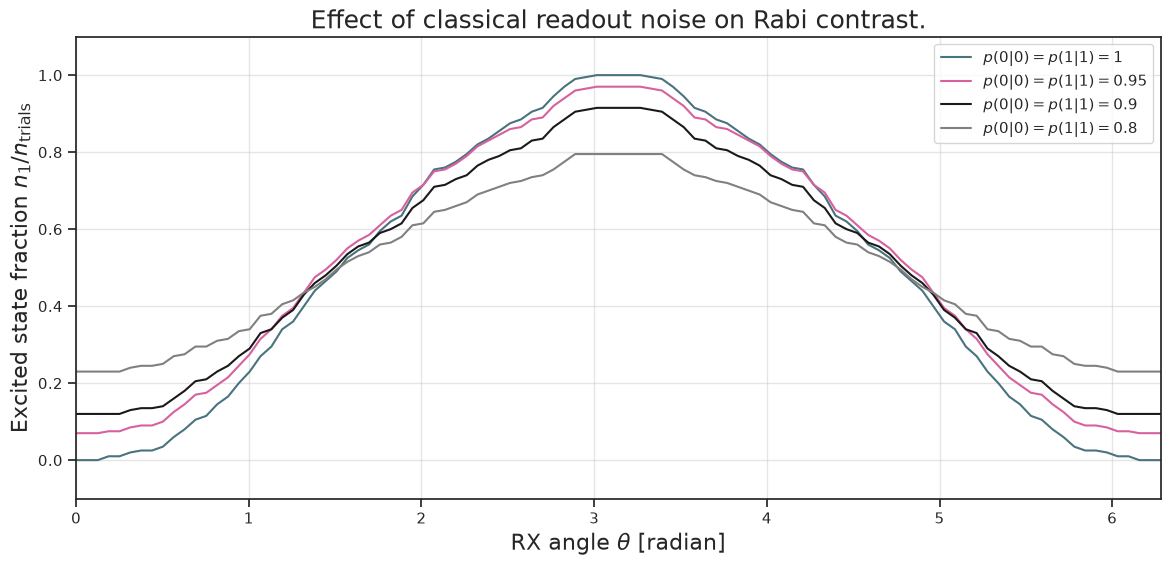

In [65]:
plt.figure(figsize=(14, 6))
for jj, (p00, c) in enumerate(zip(p00s, [DARK_TEAL, FUSCHIA, "k", "gray"])):
    plt.plot(thetas, results_rabi[:, jj]/trials, c=c, label=r"$p(0|0)=p(1|1)={:g}$".format(p00))
plt.legend(loc="best")
plt.xlim(*thetas[[0,-1]])
plt.ylim(-.1, 1.1)
plt.grid(alpha=.5)
plt.xlabel(r"RX angle $\theta$ [radian]", size=16)
plt.ylabel(r"Excited state fraction $n_1/n_{\rm trials}$", size=16)
plt.title("Effect of classical readout noise on Rabi contrast.", size=18)

### Example 2: Estimate the assignment probabilities

We estimate $P_{x'|x}$ experimentally. On a perfect quantum computer we expect the identity matrix:

In [66]:
print(estimate_assignment_probs(0, 1000, qc))

[[1. 0.]
 [0. 1.]]


On an imperfect quantum computer (simulated with noisy-readout headers). The docs use qubits 0–2 here, so we switch to a 3-qubit QVM:

In [67]:
qc = get_qc("3q-qvm")
qc.qam.random_seed = None
header0 = Program().define_noisy_readout(0, .85, .95)
header1 = Program().define_noisy_readout(1, .8, .9)
header2 = Program().define_noisy_readout(2, .9, .85)

ap0 = estimate_assignment_probs(0, 10000, qc, header0)
ap1 = estimate_assignment_probs(1, 10000, qc, header1)
ap2 = estimate_assignment_probs(2, 10000, qc, header2)

In [68]:
print(ap0, ap1, ap2, sep="\n")

[[0.8471 0.0477]
 [0.1529 0.9523]]
[[0.8002 0.0962]
 [0.1998 0.9038]]
[[0.8975 0.1486]
 [0.1025 0.8514]]


### Example 3: Correct for noisy readout

#### Correcting the Rabi signal from above

In [69]:
ap_last = np.array([[p00s[-1], 1 - p00s[-1]],
                    [1 - p00s[-1], p00s[-1]]])
corrected_last_result = [correct_bitstring_probs([1-p, p], [ap_last])[1] for p in results_rabi[:, -1] / trials]

Text(0.5, 1.0, 'Corrected contrast')

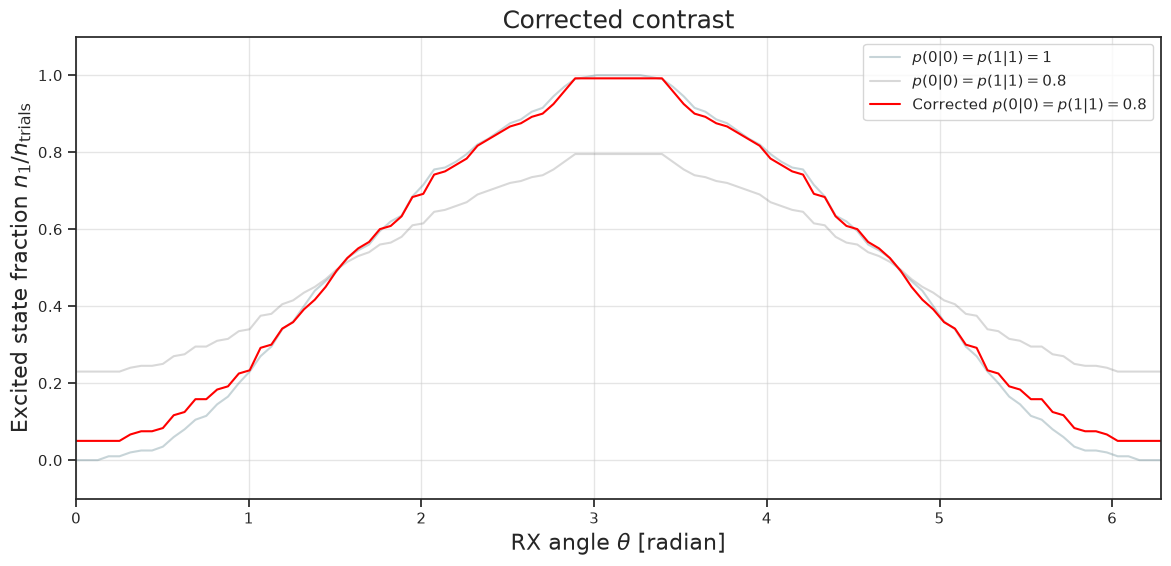

In [70]:
plt.figure(figsize=(14, 6))
for jj, (p00, c) in enumerate(zip(p00s, [DARK_TEAL, FUSCHIA, "k", "gray"])):
    if jj not in [0, 3]:
        continue
    plt.plot(thetas, results_rabi[:, jj]/trials, c=c, label=r"$p(0|0)=p(1|1)={:g}$".format(p00), alpha=.3)
plt.plot(thetas, corrected_last_result, c="red", label=r"Corrected $p(0|0)=p(1|1)={:g}$".format(p00s[-1]))
plt.legend(loc="best")
plt.xlim(*thetas[[0,-1]])
plt.ylim(-.1, 1.1)
plt.grid(alpha=.5)
plt.xlabel(r"RX angle $\theta$ [radian]", size=16)
plt.ylabel(r"Excited state fraction $n_1/n_{\rm trials}$", size=16)
plt.title("Corrected contrast", size=18)

The corrected signal is fairly noisy (and sometimes leaves $[0,1]$) because of the small sample size, $n=200$.

#### Corrupting and correcting GHZ state correlations

We prepare the GHZ state $\frac{1}{\sqrt{2}}\left[\ket{000} + \ket{111}\right]$, measure outcome probabilities with and without readout noise, and see how Pauli-Z moments (qubit correlations) are corrupted and then corrected.

In [71]:
from pyquil.quilbase import Declare
from pyquil.gates import MEASURE

ghz_prog = Program(
    Declare("ro", "BIT", 3),
    H(0),
    CNOT(0, 1),
    CNOT(1, 2),
    MEASURE(0, ("ro", 0)),
    MEASURE(1, ("ro", 1)),
    MEASURE(2, ("ro", 2)),
)
ghz_prog.wrap_in_numshots_loop(10000)
print(ghz_prog)
results = qc.run(ghz_prog).get_register_map().get("ro")

DECLARE ro BIT[3]
H 0
CNOT 0 1
CNOT 1 2
MEASURE 0 ro[0]
MEASURE 1 ro[1]
MEASURE 2 ro[2]



In [72]:
header = header0 + header1 + header2
noisy_ghz = header + ghz_prog
noisy_ghz.wrap_in_numshots_loop(10000)
print(noisy_ghz)
noisy_results = qc.run(noisy_ghz).get_register_map().get("ro")

DECLARE ro BIT[3]
PRAGMA READOUT-POVM 0 "(0.85 0.050000000000000044 0.15000000000000002 0.95)"
PRAGMA READOUT-POVM 1 "(0.8 0.09999999999999998 0.19999999999999996 0.9)"
PRAGMA READOUT-POVM 2 "(0.9 0.15000000000000002 0.09999999999999998 0.85)"
H 0
CNOT 0 1
CNOT 1 2
MEASURE 0 ro[0]
MEASURE 1 ro[1]
MEASURE 2 ro[2]



**Uncorrupted** probability of $\ket{000}$ and $\ket{111}$ — each should be ≈ 1/2:

In [73]:
probs = estimate_bitstring_probs(results)
probs[0, 0, 0], probs[1, 1, 1]

(0.494, 0.506)

**Corrupted** probabilities deviate significantly from the ideal values:

In [74]:
noisy_probs = estimate_bitstring_probs(noisy_results)
noisy_probs[0, 0, 0], noisy_probs[1, 1, 1]

(0.3092, 0.361)

**Corrected** probabilities are much closer to ideal:

In [75]:
corrected_probs = correct_bitstring_probs(noisy_probs, [ap0, ap1, ap2])
corrected_probs[0, 0, 0], corrected_probs[1, 1, 1]

(0.5087130435950528, 0.4882403713695895)

Estimate $\langle Z_0^{j} Z_1^{k} Z_2^{\ell}\rangle$ for $jk\ell = 100, 010, 001$ from **non-noisy** data — we expect these all to be very small:

In [76]:
zmoments = bitstring_probs_to_z_moments(probs)
zmoments[1, 0, 0], zmoments[0, 1, 0], zmoments[0, 0, 1]

(-0.01200000000000001, -0.01200000000000001, -0.01200000000000001)

…and for $jk\ell = 110, 011, 101$ — we expect these all to be close to 1:

In [77]:
zmoments[1, 1, 0], zmoments[0, 1, 1], zmoments[1, 0, 1]

(1.0, 1.0, 1.0)

The same moments from **noise-corrected** data:

In [78]:
zmoments_corr = bitstring_probs_to_z_moments(corrected_probs)
zmoments_corr[1, 0, 0], zmoments_corr[0, 1, 0], zmoments_corr[0, 0, 1]

(0.014510883162371702, 0.006818181818181723, 0.013486446788623374)

In [79]:
zmoments_corr[1, 1, 0], zmoments_corr[0, 1, 1], zmoments_corr[1, 0, 1]

(0.9943679350421905, 0.9859176792629187, 1.0075280455534599)

Correction restores the contrast of multi-qubit observables, though it can give slightly non-physical values; more samples reduce this.

## Alternative: a global Pauli error model

The QVM can also emulate **parametric Pauli noise**, defined by six probabilities:

- $P_X$, $P_Y$, $P_Z$ — probability of a Pauli $X$, $Y$ or $Z$ being applied to each qubit after every gate (gate noise)
- $P_X'$, $P_Y'$, $P_Z'$ — probability of a Pauli $X$, $Y$ or $Z$ being applied to a qubit right before it's measured (measurement noise)

In [80]:
noisy_qc = get_qc("1q-qvm")
noisy_qc.qam.gate_noise = (0.2, 0.0, 0.0)
noisy_qc.qam.measurement_noise = (0.2, 0.0, 0.0)

Apply an `X` gate and measure. Without noise we should always get `1`:

In [81]:
p = Program(
    Declare("ro", "BIT", 1),
    X(0),
    MEASURE(0, ("ro", 0)),
).wrap_in_numshots_loop(10)

qc = get_qc("1q-qvm")
print("Without Noise:")
print(qc.run(p).get_register_map().get("ro"))
print("With Noise:")
print(noisy_qc.run(p).get_register_map().get("ro"))

Without Noise:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]
With Noise:
[[0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]]


## Part 6: Advanced Usage

# pyQuil Tutorial: Advanced Usage

*Condensed from the [pyQuil docs, v4.17](https://pyquil-docs.rigetti.com/en/stable/advanced_usage.html).*

In [82]:
import os
# Uncomment to point pyQuil at servers on other hosts/ports (set before creating a QuantumComputer)
# os.environ["QCS_SETTINGS_APPLICATIONS_QVM_URL"] = "http://127.0.0.1:5000"
# os.environ["QCS_SETTINGS_APPLICATIONS_QUILC_URL"] = "tcp://127.0.0.1:5555"
print({k: v for k, v in os.environ.items() if k.startswith("QCS_")})

{}


## Multithreading

`QuantumComputer` objects are thread-safe and can be shared across threads. `Program` and `EncryptedProgram` are **not** thread-safe — `copy()` them before using them concurrently.

> The QVM processes requests in parallel; a QPU may process them sequentially or in parallel, depending on the qubits used.

If large batches time out on a QPU, raise `execution_timeout` (in seconds) in `get_qc()`.

**Recommendation:** use at least 2× parallelism to keep the QVM or QPU fully busy. Prefer thread pools; pyQuil has no asyncio API.

The docs example targets `Aspen-M-3` (requires QCS); here it runs on a local QVM:

In [83]:
import warnings
from pyquil._deprecation import PyQuilDeprecationWarning
# Hide pyQuil 4.22's notices that the QVM is deprecated in favour of pyQuil v5
# (the QVM still works; see 0_Jupyter_Pykernel_from_Container_image.ipynb).
warnings.filterwarnings("ignore", category=PyQuilDeprecationWarning)

from multiprocessing.pool import ThreadPool

from pyquil import get_qc, Program
from pyquil.api import QCSClient

qc = get_qc("2q-qvm")  # docs: get_qc("Aspen-M-3")  # Requires QCS access


def run(program: Program):
    return qc.run(qc.compile(program)).get_register_map().get("ro")


programs = [
    Program(
        "DECLARE ro BIT",
        "RX(pi) 0",
        "MEASURE 0 ro",
    ).wrap_in_numshots_loop(10),
] * 20

with ThreadPool(5) as pool:
    results = pool.map(run, programs)

for i, result in enumerate(results):
    print(f"Results for program {i}:\n{result}\n")

Results for program 0:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 1:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 2:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 3:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 4:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 5:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 6:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 7:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 8:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 9:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 10:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 11:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 12:
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]

Results for program 13

## Alternative QPU endpoints

Rigetti QCS supports alternative endpoints for QPU access — useful, for example, for mock endpoints that simulate execution without an active reservation. Pass an `endpoint_id` wherever a `quantum_processor_id` goes. Compilation behaves the same as with the default endpoint, but execution goes through the alternate service, so don't treat results as meaningful.

> *(Requires QCS access — see `2_experiment.ipynb`.)*

## Using libquil for quilc and QVM

> This feature is experimental and may not work on all platforms.

[libquil](https://github.com/rigetti/libquil) provides quilc and QVM as a library, so no server processes are needed. After installing libquil, install a compatible `qcs-sdk-python`:

```text
poetry run pip install --config-settings=build-args='--features libquil' qcs-sdk-python --force-reinstall --no-binary qcs-sdk-python
```

Check whether libquil is available:

In [84]:
from pyquil.diagnostics import get_report
print(get_report())

pyQuil version: 4.22.0
qcs-sdk-python version: 0.21.22
Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Python implementation: cpython
Python implementation version: 3.12.3
Python C API version: 1013
Python executable: /opt/venv/bin/python
venv prefix: /opt/venv
platform: linux
qcs-sdk-rust version: 0.25.17
rustc version: rustc 1.91.1 (ed61e7d7e 2025-11-07)
features: EXPERIMENTAL, PYTHON, TRACING, TRACING_CONFIG, TRACING_OPENTELEMETRY
qcs:
  address: https://api.qcs.rigetti.com
  network reachable: true
  authentication: failure:  (no status code): error in refresh_qcs_token: Requested an access token for a configuration without credentials.
quilc:
  address: tcp://127.0.0.1:5555
  version: 1.23.0
  available: true
qvm:
  address: http://127.0.0.1:5000
  version: 1.17.1 [cf3f91f]
  available: true
libquil:
  available: false
  quilc version: -
  qvm version: -

   



The end of the report should look like:

```text
libquil:
    available: true
    quilc version: 1.27.0
    qvm version: 1.17.2 (077ba23)
```

If `available: true`, pass libquil clients to `get_qc()`:

> *(Only runs if the diagnostics report above shows `libquil: available: true`; this container doesn't have libquil compiled in, so this is shown but not executed here.)*

```python
# Only works if the report above shows `available: true`
from pyquil import get_qc
from qcs_sdk.compiler.quilc import QuilcClient
from qcs_sdk.qvm import QVMClient

qc = get_qc("8q-qvm", quilc_client=QuilcClient.new_libquil(), qvm_client=QVMClient.new_libquil())
```

## Using qubit placeholders

> `QubitPlaceholder` gives you much the same thing as writing a function that returns a `Program` and takes qubit indices as arguments.

Normally pyQuil identifies qubits with integers:

In [85]:
from pyquil import Program
from pyquil.gates import CNOT, H
print(Program(H(0), CNOT(0, 1)))

H 0
CNOT 0 1



On near-term QPUs the specific physical qubits matter. To write a program once and run it on different qubits, use `QubitPlaceholder`s:

In [86]:
from pyquil.quilatom import QubitPlaceholder
q0 = QubitPlaceholder()
q1 = QubitPlaceholder()
p = Program(H(q0), CNOT(q0, q1))
print(p)

H Placeholder(QubitPlaceholder(0x8FDE0D0))
CNOT Placeholder(QubitPlaceholder(0x8FDE0D0)) Placeholder(QubitPlaceholder(0x8FB2380))



### Addressing qubits

A program with unresolved placeholders can't run — they must be mapped to physical qubits first. `address_qubits()` maps them to 0…N by default, skipping indices already in use:

In [87]:
from pyquil.quil import address_qubits
print(address_qubits(p))

H 0
CNOT 0 1



Or give an explicit mapping:

In [88]:
print(address_qubits(p, qubit_mapping={
    q0: 14,
    q1: 19,
}))

H 14
CNOT 14 19



Alternatively, `resolve_placeholders_with_custom_resolvers()` takes functions that receive a placeholder and return a fixed value, or `None` to leave it unresolved:

In [89]:
from typing import Optional
from pyquil import get_qc

q0 = QubitPlaceholder()
q1 = QubitPlaceholder()
p = Program(H(q0), CNOT(q0, q1))
qc = get_qc("2q-qvm")


def qubit_resolver(placeholder: QubitPlaceholder) -> Optional[int]:
    if placeholder == q0:
        return 0
    if placeholder == q1:
        return None


p.resolve_placeholders_with_custom_resolvers(qubit_resolver=qubit_resolver)
print(p)

H 0
CNOT 0 Placeholder(QubitPlaceholder(0x9F5F440))



### Requesting a register of qubit placeholders

`QubitPlaceholder.register()` creates a whole register at once:

In [90]:
qbyte = QubitPlaceholder.register(8)
p_evens = Program(H(q) for q in qbyte)
print(address_qubits(p_evens, {q: i*2 for i, q in enumerate(qbyte)}))

H 0
H 2
H 4
H 6
H 8
H 10
H 12
H 14



## Classical control flow

> Dynamic control flow can have unexpected effects on readout data. See *Accessing raw execution data* in the docs.

### While loops

1. Declare a register to act as the loop's boolean test.
2. Initialize it to `1` (the loop preamble).
3. Write the loop body as a separate `Program`.
4. Use `while_do()` to add the control flow.
5. Call `resolve_label_placeholders()` to resolve the label placeholders it inserted.

In [91]:
from pyquil import Program
from pyquil.gates import *

# Initialize the Program and declare a 1 bit memory space for our boolean flag
outer_loop = Program()
flag_register = outer_loop.declare('flag_register', 'BIT')

# Set the initial flag value to 1
outer_loop += MOVE(flag_register, 1)

# Define the body of the loop with a new Program
inner_loop = Program()
inner_loop += Program(X(0), H(0))
inner_loop += MEASURE(0, flag_register)

# Run inner_loop in a loop until flag_register is 0
outer_loop.while_do(flag_register, inner_loop)
outer_loop.resolve_label_placeholders()

print(outer_loop)

DECLARE flag_register BIT[1]
MOVE flag_register[0] 1
LABEL @START_0
JUMP-UNLESS @END_0 flag_register[0]
X 0
H 0
MEASURE 0 flag_register[0]
JUMP @START_0
LABEL @END_0



Classical instructions you can use on registers include:

- `NOT` — flips a classical bit
- `AND` — operates on two classical bits
- `IOR` — operates on two classical bits
- `MOVE` — moves a classical bit's value to another address
- `EXCHANGE` — swaps two classical bits' values

> You can build "numshots" loops in pure Quil this way; see `with_loop()` and *Build a fixed-count loop with Quil* in the docs.

### If, then

`if_then()` takes a test register and a program for each branch:

In [92]:
# Declare our memory spaces
branching_prog = Program()
ro = branching_prog.declare('ro', 'BIT')
test_register = branching_prog.declare('test_register', 'BIT')

# Construct each branch of our if-statement. We can have empty branches
# simply by having empty programs.
then_branch = Program(X(0))
else_branch = Program()

# Construct our program so that the result in test_register is equally likely to be a 0 or 1
branching_prog += H(1)
branching_prog += MEASURE(1, test_register)

# Add the conditional branching
branching_prog.if_then(test_register, then_branch, else_branch)

# Measure qubit 0 into our readout register
branching_prog += MEASURE(0, ro)
branching_prog.resolve_label_placeholders()

print(branching_prog)

DECLARE ro BIT[1]
DECLARE test_register BIT[1]
H 1
MEASURE 1 test_register[0]
JUMP-WHEN @THEN_0 test_register[0]
JUMP @END_0
LABEL @THEN_0
X 0
LABEL @END_0
MEASURE 0 ro[0]



Run it several times and look at the test register:

In [93]:
from pyquil import get_qc

qc = get_qc("2q-qvm")
branching_prog.wrap_in_numshots_loop(10)
result = qc.run(branching_prog)
print(result.get_register_map()['test_register'])

[[1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]]


### Sentinel-based loop

Combining loops and conditionals gives a loop that repeats until a condition is met. Here the body prepares and measures a Bell state, and we repeat until both qubits read `0`.

In [94]:
# Import some types we'll use
from typing import Optional, Tuple

# We'll use numpy to help us validate our results
import numpy as np

# We'll need to create a program and define an executor
from pyquil import Program, get_qc
# We'll use these gates in our program
from pyquil.gates import CNOT, H, X
# We'll also need the help of a few control flow instructions
from pyquil.quilbase import Halt, Qubit, MemoryReference, JumpTarget, Jump
from pyquil.quilatom import Label

#### The program body

The repeating body prepares a Bell state and measures both qubits into memory:

In [95]:
def body(qubits: Tuple[Qubit, Qubit], measures: MemoryReference) -> Program:
    """Constructs a bell state between the given qubit and measures them into the given memory reference."""
    program = Program(H(qubits[0]), CNOT(*qubits))
    program.measure_all(*zip(qubits, measures))
    return program

#### Resetting state

If either qubit measured `1`, flip it back with an `X`:

In [96]:
def reset_bell_state(qubits: Tuple[Qubit, Qubit], measures: MemoryReference) -> Program:
    """Resets the state of the qubits if either of them measured to 1."""
    program = Program()
    program.if_then(measures[0], Program(X(qubits[0])))
    program.if_then(measures[1], Program(X(qubits[1])))
    return program

#### Enforcing a sentinel condition

End the program (with `Halt`) if the memory reference is `0`; otherwise reset and jump back:

In [97]:
def enforce_sentinel(mem_ref: MemoryReference, else_program: Program) -> Program:
    """Ends the program if mem_ref is 0, otherwise executes else_program."""
    program = Program()
    # We use the `if_then` method here to help us construct our branch. As described above,
    # `if_then` takes a memory reference and two programs. It constructs a branch that
    # runs the first program if `mem_ref` is 1, otherwise it runs the second program.
    # Since we want to end the program if `mem_ref` is 0, we pass in our HALTing
    # program as the second program and the alternative branch as the first.
    program.if_then(mem_ref, else_program, Program(Halt()))
    return program

#### Putting it all together

In [98]:
def sentinel_program(qubits: Tuple[Qubit, Qubit]) -> Program:
    # Create a label to reference the start of the program
    start_label = Label("start-loop")

    # Use the label to create a jump target at the beginning of the program
    program = Program(JumpTarget(start_label))

    # Declare a register to measure the qubits into
    measures = program.declare("measures", "BIT", 2)

    # Add the loop body to our program
    program += body(qubits, measures)

    # If the sentinel condition isn't met, then we:
    reset = Program(
        # Reset the state of our qubits
        reset_bell_state(qubits, measures),
        # Jump back to the start of the program
        Jump(start_label)
    )

    # Finally, if both Qubits measured to 0 (our sentinel), then we want to end the program
    # Otherwise, we try again.
    program += enforce_sentinel(measures[0], reset)

    # We used pyQuil to construct some of the branches for us, those methods use label placeholders
    # to avoid conflicts with existing labels in the program, so we resolve those placeholders here.
    program.resolve_label_placeholders()
    return program

#### Testing our program

Run 1000 shots on a QVM and check that the `measures` register contains only 0s:

In [99]:
qubits = (Qubit(0), Qubit(1))

qc = get_qc("2q-qvm")
program = sentinel_program(qubits)
program.wrap_in_numshots_loop(1000)
print(program.out())
results = qc.run(program)
measures = results.get_register_map()["measures"]

assert np.all(measures == 0)
print("All shots ended in the sentinel state 00")

DECLARE measures BIT[2]
LABEL @start-loop
H 0
CNOT 0 1
MEASURE 0 measures[0]
MEASURE 1 measures[1]
JUMP-WHEN @THEN_0 measures[0]
HALT
JUMP @END_0
LABEL @THEN_0
JUMP-WHEN @THEN_1 measures[0]
JUMP @END_1
LABEL @THEN_1
X 0
LABEL @END_1
JUMP-WHEN @THEN_2 measures[1]
JUMP @END_2
LABEL @THEN_2
X 1
LABEL @END_2
JUMP @start-loop
LABEL @END_0

All shots ended in the sentinel state 00


## Pauli operator algebra

`PauliTerm` and `PauliSum` represent sums of Pauli products such as

$$\sigma = \tfrac{1}{2}I - \tfrac{3}{4}X_0Y_1Z_3 + (5-2i)Z_1X_2$$

In [100]:
from pyquil.paulis import ID, sX, sY, sZ

# Pauli term takes an operator "X", "Y", "Z", or "I"; a qubit to act on, and
# an optional coefficient.
a = 0.5 * ID()
b = -0.75 * sX(0) * sY(1) * sZ(3)
c = (5-2j) * sZ(1) * sX(2)

# Construct a sum of Pauli terms.
sigma = a + b + c
print(f"sigma = {sigma}")

sigma = (0.5+0j)*I + (-0.75+0j)*X0*Y1*Z3 + (5-2j)*Z1*X2


Their main use is building exponentials $\exp[-i\beta\sigma]$ as parameterized Quil programs. There are also utilities for finding commuting subgroups and for Suzuki–Trotter approximations up to fourth order. Arithmetic simplifies automatically:

In [101]:
from pyquil.paulis import exponential_map

sigma_cubed = sigma * sigma * sigma
print(f"Simplified: {sigma_cubed}\n")

# Produce Quil code to compute exp[iX]
H = -1.0 * sX(0)
print(f"Quil to compute exp[iX] on qubit 0:\n"
      f"{exponential_map(H)(1.0)}")

Simplified: (32.46875-30j)*I + (-16.734375+15j)*X0*Y1*Z3 + (71.5625-144.625j)*Z1*X2

Quil to compute exp[iX] on qubit 0:
H 0
RZ(-2) 0
H 0



`exponential_map()` returns a function, so you can supply the multiplicative constant later — common in variational algorithms. Compute $\exp[-i\alpha H]$ for several α:

In [102]:
expH = exponential_map(H)
print(f"0:\n{expH(0.0)}\n")
print(f"1:\n{expH(1.0)}\n")
print(f"2:\n{expH(2.0)}")

0:
H 0
RZ(0) 0
H 0


1:
H 0
RZ(-2) 0
H 0


2:
H 0
RZ(-4) 0
H 0



`exponential_map` also works with parametric compilation — the angle becomes a declared `REAL` parameter:

In [103]:
from pyquil import Program

ham = sZ(0) * sZ(1)
prog = Program()
theta = prog.declare('theta', 'REAL')
prog += exponential_map(ham)(theta)
print(prog)

DECLARE theta REAL[1]
CNOT 0 1
RZ(2*theta[0]) 1
CNOT 0 1



### Kill the servers after use in **0_Jupyter_Pykernel_from_Container_image** notebook